# Quantum Simulation of the XXZ Spin Chain using Trotterized Quantum Circuits
_by Bhoopesh Dosieah, Saqib Umair, Anay Chadha, Shailesh Devarasu, Akshat Dalmia and Hamish Cranston_

## Quantum Computing Project

## Public portfolio note

This notebook is the original group analysis prepared for public portfolio use. Student identification numbers and a hard-coded IBM Quantum API credential have been removed. The scientific code, outputs and group contribution record are otherwise preserved.


## 1. Introduction

### 1.1 Problem

Understanding the non-equilibrium dynamics of interacting quantum many-body systems is a central challenge in modern physics [1]. In particular, a key question is how local disturbances propagate through strongly correlated systems and how information spreads across a lattice.

In this project, we investigate the dynamics of a one-dimensional quantum spin chain described by the XXZ Heisenberg model. This model captures nearest-neighbour interactions between spin-$\tfrac{1}{2}$ particles and provides a minimal framework for studying quantum transport, correlations, and dynamical behaviour in condensed matter systems.

A local perturbation is introduced at a single lattice site, and the subsequent time evolution of the system is analysed. In interacting quantum systems, such disturbances do not spread instantaneously but instead propagate with a finite velocity. This leads to characteristic “light-cone”-like structures in space–time representations, consistent with the Lieb–Robinson bound, which establishes an effective speed limit for information propagation in quantum systems [2].

The central question addressed in this project is:

> *How does a local perturbation propagate in an interacting quantum system, and what structures emerge in its space–time evolution?*

---

### 1.2 Quantum Computers

Simulating quantum many-body systems on classical computers is fundamentally challenging due to the exponential growth of the Hilbert space with system size. As the number of particles increases, the computational resources required to store and evolve the quantum state become prohibitively large.

Quantum computers provide a natural platform for addressing this problem, as they directly manipulate quantum states and implement unitary time evolution using quantum circuits [3]. Instead of explicitly storing the full state vector, quantum hardware encodes the system in qubits and evolves it through sequences of quantum gates.

In this project, the time evolution operator is approximated using the Suzuki–Trotter decomposition, which expresses the exponential of the Hamiltonian as a product of local unitary operations [5]. This method is particularly suitable for spin-chain models, where the Hamiltonian consists of sums of nearest-neighbour interactions that can be efficiently mapped to two-qubit gates.

This framework enables us to simulate the dynamics of the system using quantum circuits and to compare ideal (noise-free) simulations with noisy implementations, allowing us to assess the impact of hardware imperfections on quantum dynamics [4].

---

### Goal

The primary goal of this project is to simulate and analyse the dynamical evolution of a one-dimensional quantum spin chain following a local perturbation.

Specifically, we aim to:

- Characterise the propagation of local excitations through the lattice  
- Analyse the time-dependent behaviour of site-resolved observables  
- Visualise the dynamics using space–time representations and Fourier analysis  
- Compare classical exact, ideal quantum, and noisy quantum simulations  

Through this study, we aim to gain insight into information propagation in interacting quantum systems and evaluate the capabilities and limitations of current quantum computing platforms.

In [ ]:
# Import numerical library for array operations and linear algebra
import numpy as np
# Import plotting library for visualising results (e.g., space-time diagrams)
import matplotlib.pyplot as plt
# Import linear algebra routines (e.g., matrix exponentiation for exact evolution)
import scipy.linalg as la

# Import core Qiskit tools for building and simulating quantum circuits
from qiskit import QuantumCircuit, transpile
# Import tools for representing quantum operators and states
from qiskit.quantum_info import SparsePauliOp, Statevector
# Import estimator primitive for computing expectation values from statevectors
from qiskit.primitives import StatevectorEstimator
# Import Aer simulator estimator (used for noisy or high-performance simulation)
from qiskit_aer.primitives import EstimatorV2 as AerEst

# Import IBM Quantum runtime service and estimator for running circuits on real hardware
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2, EstimatorOptions
# Import preset transpiler pass managers for optimising circuits for specific backends
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

## 2. Model

### 2.1 XXZ Hamiltonian

In this project, the system is modelled as a one-dimensional chain of spin-$\tfrac12$ particles with nearest-neighbour interactions. The dynamics are described by the XXZ Hamiltonian

$$
H = - \sum_{i=1}^{L-1} \left( X_i \otimes X_{i+1} + Y_i \otimes Y_{i+1} + J_z Z_i \otimes Z_{i+1} \right),
$$

where $X_i$, $Y_i$, and $Z_i$ are the Pauli operators acting on site $i$, $J_z$ is the anisotropy parameter, and $L$ is the number of lattice sites.

The $XX$ and $YY$ terms describe spin coupling in the transverse directions, while the $ZZ$ term describes the interaction along the $z$-direction. The parameter $J_z$ controls the relative strength of the $ZZ$ part of the Hamiltonian and therefore plays an important role in determining the behaviour of the system.

In this work, open boundary conditions are used, so the interaction only runs between neighbouring sites inside the chain. This means there is no coupling between the first and last spins, and the chain has two physical ends.

### 2.2 Initial states and local perturbation

The initial state depends on the value of $J_z$. For the regime $J_z > 1$, one of the fully polarised product states is used,

$$
|0\rangle^{\otimes L}
\qquad \text{or} \qquad
|1\rangle^{\otimes L}.
$$

For the regime $J_z < -1$, the initial state is taken to be the alternating Néel-like state

$$
|10\rangle^{\otimes L/2} = |101010\ldots\rangle.
$$

These states are chosen because they match the ordered configurations associated with the two regimes of the Hamiltonian.

To produce non-trivial dynamics, a local rotation is applied to one lattice site, usually near the middle of the chain. This rotates one spin into the $(x,y)$ plane and creates a local perturbation. The system is then evolved in time under the XXZ Hamiltonian.

If the initial state after the local rotation is written as $|\psi(0)\rangle$, then the time-evolved state is

$$
|\psi(t)\rangle = e^{-iHt} |\psi(0)\rangle.
$$

This allows the spreading of the local perturbation through the chain to be followed as time increases.

### 2.3 Observables

The main quantities measured in this project are the site-resolved spin expectation values

$$
\langle X_i(t) \rangle, \qquad
\langle Y_i(t) \rangle, \qquad
\langle Z_i(t) \rangle.
$$

These represent the average spin orientation at site $i$ along the $x$-, $y$-, and $z$-directions at time $t$. In general, the expectation value of an operator $O$ is written as

$$
\langle O(t) \rangle = \langle \psi(t) | O | \psi(t) \rangle.
$$

By evaluating these observables at each timestep and for each lattice site, it is possible to build space-time plots that show how the perturbation evolves across the spin chain. These observables therefore provide the main information used to study the dynamics in this report[10].

In [ ]:
# Defining the XXZ Hamiltonian
def XXZ_hamil(L, Jz):

    paulis = []
    coeffs = []
    # Loop over nearest-neighbour pairs only
    # Since I am using open boundary conditions,
    # the interaction goes only from site 0 to site L-2
    for i in range(L-1):

 # Neighbouring site
        j = (i+1)%L
# Start from identity on all sites
        XX = ['I']*L
        YY = ['I']*L
        ZZ = ['I']*L
# Place Pauli operators on neighbouring sites i and j
        XX[i], XX[j] = 'X','X'
        YY[i], YY[j] = 'Y','Y'
        ZZ[i], ZZ[j] = 'Z','Z'
# Add XX term
        paulis.append("".join(XX))
        coeffs.append(-1)
# Add YY term
        paulis.append("".join(YY))
        coeffs.append(-1)
# Add ZZ term
# Jz controls how strong the ZZ interaction is
        paulis.append("".join(ZZ))
        coeffs.append(-Jz)

    H = SparsePauliOp(paulis, coeffs)

    return H

In [ ]:
def prepare_initial_state(L, state_type, theta=(np.pi)/2, phi=0):
    qc = QuantumCircuit(L)
 # Prepare the required initial state
    if state_type == "all_0":
        pass
    elif state_type == "all_1":
        for i in range(L):
            qc.x(i)
    elif state_type == "neel_10":
        for i in range(0, L, 2):
            qc.x(i)
    else:
        raise ValueError(f"Unknown state type: {state_type}")
  # Apply a local rotation at the middle site
  # This creates the local perturbation
    mid = L // 2
    qc.ry(theta, mid)
    qc.rz(phi, mid)

    return qc

In [ ]:
def local_pauli_operator(L, site, pauli):
    if pauli not in ["X", "Y", "Z"]:
        raise ValueError("pauli must be 'X', 'Y', or 'Z'")
 # Put the chosen Pauli on one site
 # and identity on all the others
    label = ["I"] * L
    label[site] = pauli
    return SparsePauliOp("".join(label))

## 3. Quantum Circuit Time Evolution

### 3.1 What Are We Doing?

In quantum mechanics, a system changes over time according to the Schrödinger equation. If the rules governing the system (the Hamiltonian) don't change with time, then the state |ψ(0)⟩ evolves by applying a unitary operator:

$$U(t) = e^{-iHt}$$

We want to simulate a chain of quantum spins (qubits) sitting in a line, where each spin is magnetically coupled to its neighbor. The model we use is called the **XXZ model**:

$$H = -\sum_{i=1}^{L}(X_i \otimes X_{i+1} + Y_i \otimes Y_{i+1} + J_z Z_i \otimes Z_{i+1})$$

Here's what this means:

- **X, Y, Z** are the Pauli matrices — they describe how a spin can interact with its neighbor in three different directions.
- The sum runs over every neighboring pair in the chain. If you have L qubits, there are L−1 bonds.
- **Jz** controls how strong the ZZ interaction is compared to XX and YY. When Jz = 1, all three directions are equally strong (this is the isotropic Heisenberg model).
- The **minus sign** out front matters, it sets the correct direction of phase rotation when we turn this into gates.


### 3.2 The Trotter Method: Chopping Time Into Small Steps

### The core problem

To simulate time evolution on a quantum computer, we need to turn the big operator e^{−iHt} into a sequence of small two-qubit gates. But we can't just split the exponential freely, because the different bond terms in H **don't commute** they interfere with each other. Specifically, bond (0,1) and bond (1,2) share qubit 1, so their contributions can't be applied independently without error.

### The trick: colour the bonds

We split all the bonds into two groups:

- **Even bonds:** (0,1), (2,3), (4,5), ...
- **Odd bonds:** (1,2), (3,4), (5,6), ...

Within each group, no two bonds share a qubit. That means all the even bonds commute with each other (they don't interfere), and all the odd bonds commute with each other. This lets us apply all bonds in one group simultaneously without conflicts

An even bond and an odd bond **do** share a qubit at their boundary. So when we apply even bonds and then odd bonds separately, we're *pretending* they don't interfere. This pretending introduces a small error.

### Two levels of accuracy

We implemented two versions of this approximation to see how accuracy depends on the time step size dt:

**First-Order Trotter** — Apply even bonds, then odd bonds:

$$U(dt) \approx e^{-iH_{odd}\,dt}\; e^{-iH_{even}\,dt}$$

This is the simplest approach. The error per step scales as **O(dt²)**. Think of it as: we lied about the even and odd groups being independent, and the size of that lie is proportional to dt squared.

**Second-Order (Symmetric) Trotter** — Sandwich the odd bonds between two half-steps of even bonds:

$$U(dt) \approx e^{-iH_{even}\frac{dt}{2}}\; e^{-iH_{odd}\,dt}\; e^{-iH_{even}\frac{dt}{2}}$$

This symmetric pattern makes the leading errors from the left half and right half cancel each other out — like noise cancellation. The remaining error per step drops to **O(dt³)**, which is much smaller for the same dt. The tradeoff is a slightly deeper circuit (three layers instead of two).


### 3.3 The Actual Circuit

We built the circuit by hand rather than using an automatic compiler, because we wanted full control over which gates run where. By explicitly defining the `even_bonds` and `odd_bonds` arrays, we make sure that the non-overlapping bonds can run at the same time on real hardware, keeping the circuit as short as possible.

### What one bond looks like

For a single bond between qubits i and j, the Hamiltonian contributes three terms: XX + YY + Jz·ZZ. On a single isolated pair of qubits, these three terms **commute with each other**, so we can split them into three separate rotation gates **with zero additional error**:

1. **RXX gate** — handles the XX coupling. Defined as e^{−i(θ/2) X_i X_j}. We pass θ = −2dt.
2. **RYY gate** — handles the YY coupling. Defined as e^{−i(θ/2) Y_i Y_j}. We pass θ = −2dt.
3. **RZZ gate** — handles the Jz·ZZ coupling. Defined as e^{−i(θ/2) Z_i Z_j}. We pass θ = −2·Jz·dt.

This is the `_apply_xxz_bond` function — it loops over every bond in a group and stamps down these three gates.

### Putting it all together

The `suzuki_trotter` function applies one Trotter step:

- **Order 1:** calls `_apply_xxz_bond` on the even bonds with dt, then on the odd bonds with dt.
- **Order 2:** calls it on even bonds with dt/2, then odd bonds with dt, then even bonds with dt/2 again.

The `trotter_circuit` function just repeats `suzuki_trotter` in a loop once for each time step — to build the full evolution circuit.

### Measuring the results

The `quantum_dynamics` function is the full pipeline. For each time step t, it:

1. Prepares the initial state.
2. Builds the Trotter circuit up to time t.
3. Measures the expectation value of X, Y, and Z on every qubit. (To measure X or Y, you add a basis-change gate before measuring — a Hadamard for X, or an S†·H for Y.)
4. Stores the results in three grids (one for each Pauli direction), shaped as time × sites.



In [ ]:
"""
Applies one Suzuki-Trotter step of the XXZ Heisenberg model to a circuit.
The XXZ Hamiltonian has equal XX and YY couplings (set to 1) and a tunable
ZZ coupling (jz). Bonds are split into even/odd layers to respect locality.
"""

def suzuki_trotter(qc: QuantumCircuit, num_qubits: int, jz: float, dt: float,
                   order: int = 1,) -> None:

    if order not in (1, 2):
        raise ValueError("Only order 1 and 2 are supported.")

    # Partition nearest neighbour bonds into two non-overlapping sets so that bonds with same layer commutes

    even_bonds = []
    for i in range(0, num_qubits - 1, 2):
        even_bonds.append((i, i+1))  # (0,1), (2,3), ...
    odd_bonds = []
    for i in range(1, num_qubits - 1, 2):
        odd_bonds.append((i, i+1))  # (1,2), (3,4), ...

    def _apply_xxz_bond(bonds, dt_b):
    # Each bond is implemented with three two-qubit rotations
    # The factors of -2 arise from the standard Qiskit convention (need θ = 2*dt)
        for i, j in bonds:
            qc.rxx(-2 * dt_b, i, j)
            qc.ryy(-2 * dt_b, i, j)
            qc.rzz(-2 * jz * dt_b, i, j) # jz scales ZZ

    if order == 1:
    # First-order which simply applies even then odd bonds
    # Error is O(dt²) per step due to non-commutativity between layers.
        _apply_xxz_bond(even_bonds, dt)
        _apply_xxz_bond(odd_bonds, dt)

    else:
    # Option for second-order available if needed  which does symmetric splitting E(dt/2) · O(dt) · E(dt/2)
    # Cancels the leading error term, improving accuracy to O(dt³) per step
        half = dt / 2.0
        _apply_xxz_bond(even_bonds, half)
        _apply_xxz_bond(odd_bonds, dt)
        _apply_xxz_bond(even_bonds, half)

"""
Builds the full time-evolution circuit by repeating the Trotter step.
Total simulated time = dt * steps.
"""
def trotter_circuit(H, jz, dt, steps, order = 1):
    num_qubits = H.num_qubits
    qc = QuantumCircuit(num_qubits)

    # Each iteration appends one Trotter step
    # Smaller dt (more steps) gives better accuracy but deeper circuits
    for _ in range(steps):
        suzuki_trotter(qc, num_qubits, jz, dt, order)
    return qc

In [ ]:
"""
Simulates time evolution of an XXZ spin chain and records local Pauli
expectation values at each time step. Returns three (steps × L) arrays
for <X>, <Y>, <Z> at every site and every time.
"""

def quantum_dynamics(L, Jz, state_type, dt, steps, estimator, backend=None):

    # Build the XXZ Hamiltonian and prepare the initial many-body state.
    # These are kept outside the time loop — they don't change between steps.
    H = XXZ_hamil(L, Jz)
    ini = prepare_initial_state(L, state_type)

    # Writing into pre-allocated arrays is faster than appending in a loop
    X_data = np.zeros((steps, L))
    Y_data = np.zeros((steps, L))
    Z_data = np.zeros((steps, L))

    # Build the full flat list of observables once outside the time loop
    # Order is [X_0, Y_0, Z_0, X_1, Y_1, Z_1, ...] allowing us to index with 3*site, 3*site+1, 3*site+2 later
    observables = []
    for site in range(L):
        observables.append(local_pauli_operator(L, site, "X"))
        observables.append(local_pauli_operator(L, site, "Y"))
        observables.append(local_pauli_operator(L, site, "Z"))

    for t in range(steps):

        # Rebuild the Trotter circuit for exactly t steps of evolution
        evo = trotter_circuit(H, Jz, dt, t)
        circuit = ini.compose(evo)   # prepend state prep to evolution

        if backend is not None:
        # Hardware path: transpile to native gate set and connectivity then remap observables (otherwise measure wrong qubits)
          circuit = transpile(circuit, backend)
          isa_observables = [obs.apply_layout(circuit.layout) for obs in observables]
        else:
        # Local simulator path: no transformations
          isa_observables = observables

        # Submit all 3L observables in a single estimator job to minimise overhead
        run = estimator.run([(circuit, isa_observables)])
        result = run.result()[0].data.evs    # Gives flat array of 3L expectation values

        # Make the flat array into per site and axis array
        for site in range(L):
            X_data[t, site] = result[3*site]
            Y_data[t, site] = result[3*site + 1]
            Z_data[t, site] = result[3*site + 2]

    return X_data, Y_data, Z_data

## 4. Classical Time Evolution

### 4.1 Purpose

* **Objective:** To generate an exact numerical baseline for the dynamics of the 1D Heisenberg spin chain.
* **Why it is needed:** Current quantum hardware (NISQ devices) suffers from gate noise and decoherence. We need a clean, zero-noise classical simulation to isolate and quantify these experimental errors.
* **What it measures:** It calculates the mathematically exact propagation of the system over time, providing a reliable baseline to compare against the noisy IBM quantum data.

### 4.2 Method

### The Governing Mathematics
* **The Unitary Operator:** The continuous propagation of the quantum state through time is governed by the exact unitary time evolution operator:
  $$U(t) = e^{-iHdt}$$
* **The Numerical Solver:** The simulation strictly avoids discrete time-stepping approximations by computing the exact matrix exponential using the `scipy.linalg.expm` function.
* **Internal Mechanics:** This function evaluates the dense matrix exponential using a scaling and squaring algorithm combined with a Padé approximation [6]. It scales the Hamiltonian matrix down until its norm is small enough to be evaluated to machine precision via a rational polynomial, and then iteratively squares the result to recover the full time step.

### Algorithmic Justification
This specific dense-matrix solver was deliberately chosen over alternative numerical methods to establish a flawless baseline:
* **vs. Discrete Integration (RK4 / Trotterization)[7,2]:** Standard numerical integrators like 4th-Order Runge-Kutta (RK4) or the Trotterization used in quantum circuits inherently introduce discrete truncation and commutation errors. By using the Padé approximation, the classical engine calculates the mathematically exact continuous evolution, entirely eliminating algorithmic error from the benchmark.
* **vs. Sparse Approximations (Krylov Subspace / Lanczos)[8]:** While sparse-matrix algorithms (such as Krylov subspace or Lanczos iteration) are highly memory-efficient and strictly required for systems where $L \geq 14$, they are ultimately approximation techniques. Because the full $4096 \times 4096$ complex Hamiltonian for $L=12$ easily fits within standard 32GB computational memory, the exact dense `expm` algorithm was selected. This provides maximum mathematical rigor and avoids any convergence  or instabilities associated with sparse-approximation methods.

### Quantum Circuit Parity
To ensure the classical simulation serves as a valid diagnostic tool for the IBM quantum hardware, the mathematical construction strictly mirrors the logic of the quantum gates:
* **Operator Equivalence:** The classical Hamiltonian is constructed using the Kronecker products of local Pauli matrices (e.g., $\sigma_x \otimes \sigma_x$). This strictly mirrors the exact two-qubit exchange interactions (XX, YY, ZZ gates) implemented in the quantum circuit.
* **State Preparation:** The initial state perturbation is applied using the explicit matrix representation of the single-qubit rotation gate. This ensures the classical starting vector exactly matches the quantum superposition state prepared on the hardware.
* **Parameter Synchronization:** The classical time step ($dt$) and the interaction strength ($J_z$) are explicitly synchronized with the discrete Trotterization steps and rotation angles utilized in the Qiskit environment, guaranteeing an exact comparison.

### 4.3 Limitations

### The Problem of Exponential Growth and Memory Storage
* **Exponential Scaling:** The main limitation of our exact classical approach is that the size of the math scales exponentially as $2^L$. For a 1D chain of $L$ spins, the Hamiltonian is a $2^L \times 2^L$ matrix.
* **Storing the Full Matrix:** Because we are calculating the exact mathematical exponential, we cannot use memory-saving shortcuts (like sparse matrices) that ignore the zeros. The computer must physically store every single number in the matrix in its RAM.

### Hardware Limits and the Math Function's Memory Cost
Extensive testing on a 32 GB laptop revealed a hard physical limit caused by how the `expm` math function works behind the scenes:
* **The Hidden Memory Multiplier:** The `scipy.linalg.expm` function does not just update the matrix in place. To do its complex calculations, it has to create multiple temporary copies of the matrix simultaneously to store intermediate steps. As a result, the actual RAM used is many times larger than the base size of the Hamiltonian.
* **The $L=12$ Safe Zone:** For a 12-spin system, the total dimension is $4,096$. Even with the extra copies required by the `expm` function, the matrices fit comfortably within standard system memory, resulting in fast and highly stable calculations.
* **The $L=13$ Stress Limit:** Doubling the dimension to $8,192$ pushes this memory overhead to the extreme edge of what a standard laptop can handle. The temporary copies collectively consume almost all of the 32 GB of RAM, causing severe slowdowns.
* **The $L=14$ System Failure:** At a dimension of $16,384$, the multiple large arrays required by the `expm` function instantly ask for more RAM than a 32 GB machine actually has. This memory overflow forces the computer's operating system to step in and kill the program completely before it can even finish one time step.

### Balancing Accuracy and Computational Cost
* **Why We Cannot Use Memory-Saving Methods:** To safely run $L \ge 14$ without crashing the computer, we would have to abandon the exact `expm` math and use approximation methods (like Krylov subspace methods). However, introducing approximations would defeat the whole purpose of creating a mathematically perfect, noise-free baseline to compare against the quantum hardware.
* **The Problem with Too Small a Time Step ($dt$):** While the classical engine can technically calculate an infinitely small time step ($dt \to 0$), doing so creates a massive data bottleneck. Making $dt$ extremely low dramatically increases the time it takes to run and generates gigabytes of repetitive data without showing any finer details in the physics. Therefore, we carefully balance the $dt$ to match the quantum Trotter step rather than just making it as small as possible.

In [ ]:
def classical(L, Jz, state_type, dt, n_steps):

    # Set the physics rule/ hamiltonian
    H = XXZ_hamil(L, Jz).to_matrix()

    # Set starting spin states
    ini = prepare_initial_state(L, state_type)
    psi = Statevector.from_instruction(ini).data

    # Create the time step
    U = la.expm(-1j * H * dt)

    # Prepare empty data tables
    X_data = np.zeros((n_steps, L))
    Y_data = np.zeros((n_steps, L))
    Z_data = np.zeros((n_steps, L))

    # Get the measurement tools
    obsX = [local_pauli_operator(L, site, "X").to_matrix() for site in range(L)]
    obsY = [local_pauli_operator(L, site, "Y").to_matrix() for site in range(L)]
    obsZ = [local_pauli_operator(L, site, "Z").to_matrix() for site in range(L)]

    # Loop through time steps
    for t in range(n_steps):

        # Measure spins every site
        for site in range(L):

            # Record the exact measurements
            X_data[t, site] = np.real(np.vdot(psi, obsX[site] @ psi))
            Y_data[t, site] = np.real(np.vdot(psi, obsY[site] @ psi))
            Z_data[t, site] = np.real(np.vdot(psi, obsZ[site] @ psi))

        # Move time forward now
        psi = U @ psi

    # Return the final data
    return X_data, Y_data, Z_data

## 5. Noisy Circuit Time Evolution

### 5.1 Purpose

In realistic quantum devices, ideal unitary evolution is affected by various sources of noise, including gate errors, decoherence, and measurement imperfections. To assess the robustness of our Trotterized quantum simulation, we extend our analysis to include noisy circuit execution. This allows us to evaluate whether the qualitative physics of the XXZ spin chain survives under realistic hardware conditions.

### 5.2 Method

To simulate noise, we construct an estimator using a backend informed noise model. Specifically, we initialise a runtime service and retrieve a real device backend, from which a noise aware estimator is created. This ensures that the circuit execution reflects hardware-level imperfections rather than idealized behaviour. The backend here will be same as our final IBM hardware run. Such noise models are widely used in quantum simulation studies to approximate near term device performance [12].

A key modification was required in the `quantum_dynamics` function to ensure compatibility with hardware-level execution. Unlike ideal simulators, noisy backends require circuits to be transpiled into the native gate set and qubit layout of the device. Therefore, before execution, each circuit is transpiled using the chosen backend. Additionally, since transpilation alters the qubit mapping, the observables must also be transformed using the same layout via `apply_layout`. This ensures that expectation values are computed on the correct physical qubits.

Importantly, this modification is implemented conditionally. Transpilation and observable remapping are only applied when a backend is provided. This preserves the correctness and efficiency of the ideal simulation while enabling seamless integration of noisy execution.

By comparing noisy results with ideal and exact classical simulations, we can directly observe the impact of hardware noise on quantum dynamics and assess the feasibility of such simulations on current quantum devices.


In [ ]:
"""
Creates a noise estimator by pulling the real device's noise
model, basis gates, and coupling map from IBM Quantum and injecting them
into a local Aer simulation. This lets you approximate hardware noise
without consuming real device shots.
"""

def noisy_estimator(backend_name):

    # Connect to IBM Quantum and fetch the live backend object
    service = QiskitRuntimeService()  # Picks credentials from saved account
    backend = service.backend(backend_name)

    # Build an Aer estimator that mirrors the target backend without queuing on real machine
    estimator = AerEst.from_backend(backend)

    # Backend needed for tranpile in quantum_dynamics function
    return estimator, backend

## 6. Analysis

### 6.1 Method

To analyse the system dynamics, four complementary visualisation methods were used.

The function `plot_spacetime` produces a space–time heatmap of a chosen observable across all lattice sites and time steps. This is the main tool used to visualise how the initial local perturbation spreads through the chain.

The function `plot_error_heatmap` computes the absolute difference between the exact classical results and the quantum simulation. This allows us to examine how errors build up in both time and space.

The function `plot_fourier_transform` applies a two-dimensional Fourier transform to the space–time data. This provides a momentum–frequency representation, which helps identify the dominant propagation modes in the dynamics.

The function `plot_site_comparison` compares the time evolution at a single lattice site for the classical exact, ideal quantum, and noisy quantum simulations. This gives a direct local comparison between the different methods.

Although expectation values of $\langle X_i(t) \rangle$, $\langle Y_i(t) \rangle$, and $\langle Z_i(t) \rangle$ were computed, the analysis mainly focuses on $\langle Z_i(t) \rangle$, since it provides the most stable and clearly interpretable signal across all simulation types.

In the Fourier analysis, the $k=0$ and $\omega=0$ components were removed before plotting. These components had much higher intensity than the rest of the spectrum and would otherwise dominate the colour scale, making weaker non-trivial features difficult to observe.

Together, these visualisation methods provide the basis for analysing the evolution of the local perturbation and comparing the different simulation approaches.

In [ ]:
def plot_spacetime(data, dt, observable_name="<Z>"):

    # Extract dimensions and calculate the total simulation time based on the time-step
    T_steps, L = data.shape
    physical_time = T_steps * dt

    plt.figure(figsize=(10,6))

    # Map the discrete data indices to physical site numbers and continuous time coordinates
    im = plt.imshow(data, aspect="auto", cmap="RdBu", origin="lower",
                    extent=[0, L-1, 0, physical_time])

    plt.colorbar(im, label=f"{observable_name}")
    plt.title(f"Spacetime Dynamics of {observable_name}")
    plt.xlabel("Lattice Site (i)")
    plt.ylabel("Time (t)")

    plt.tight_layout()
    plt.show()

def plot_error_heatmap(exact_data, quantum_data, dt, name):

    # Calculate the pointwise absolute difference to quantify deviation across the entire lattice
    error_matrix = np.abs(exact_data - quantum_data)

    # Reconstruct the physical time axis for the vertical scale of the heatmap
    T_steps, L = error_matrix.shape
    physical_time = T_steps * dt

    plt.figure(figsize=(10,6))

    # Use a perceptually uniform colormap (magma) to highlight small error gradients clearly
    im = plt.imshow(error_matrix, aspect="auto", cmap="magma",origin="lower",
                   extent=[0, L-1, 0, physical_time])

    plt.colorbar(im, label="|Exact − Quantum|")
    plt.title(f"Error Accumulation ({name})")
    plt.xlabel("Lattice Site (i)")
    plt.ylabel("Time (t)")

    plt.tight_layout()
    plt.show()

def plot_fourier_transform(data, name):
    # Compute the 2D Fast Fourier Transform to move from real space to frequency space
    fft_data = np.fft.fft2(data)

    # Shift the zero-frequency component to the center of the spectrum
    fft_shifted = np.fft.fftshift(fft_data)

    # Calculate the absolute magnitude to visualize signal strength across frequencies
    magnitude_spectrum = np.abs(fft_shifted)

    # Identify the central indices
    c_row = magnitude_spectrum.shape[0] // 2
    c_col = magnitude_spectrum.shape[1] // 2

    # Remove the central axes to eliminate the dominant artifact for better scaling
    magnitude_spectrum = np.delete(magnitude_spectrum, c_row, axis=0)
    magnitude_spectrum = np.delete(magnitude_spectrum, c_col, axis=1)

    plt.figure(figsize=(10,6))

    # Display the log-scaled intensity to reveal lower-energy dispersion features
    im = plt.imshow(np.log(magnitude_spectrum + 1e-10), aspect='auto', cmap='viridis',
                    origin='lower', extent=[-np.pi, np.pi, -np.pi, np.pi])

    # Add a colorbar to provide a reference for the logarithmic intensity levels
    plt.colorbar(im, label="Log Intensity")

    # Define the plot metadata including the dynamic title and axis labels
    plt.title(f"2D Fourier Spectrum (Dispersion Relation) ({name})")
    plt.xlabel("Momentum k")
    plt.ylabel("Frequency ω")

    # Adjust layout padding and render the final visualization
    plt.tight_layout()
    plt.show()

def plot_site_comparison(Z_exact, Z_plot2, Z_noisy, dt, site, name, plotno, plot2):

    # Scale the discrete time-step indices by dt to create a continuous physical time axis
    T = np.arange(Z_exact.shape[0]) * dt

    plt.figure(figsize=(10,6))

    # Pull out the data for just one specific point on the lattice to see how it moves
    plt.plot(T, Z_exact[:,site], label="Classical Exact")

    # Draw the perfect quantum simulation or IBM hardware simulation as a dashed line for easy comparison
    plt.plot(T, Z_plot2[:,site], "--", label=plot2)

    if plotno == 3: # Condition if noisy circuit is needed
    # Draw the noisy hardware results as a dotted line to show where errors creep in
        plt.plot(T, Z_noisy[:,site], ":", label="Noisy Circuit")

    plt.xlabel("Time")
    plt.ylabel("<Z>")
    plt.title(f"Spin Dynamics at Site {site} for {name}")

    plt.legend()
    plt.tight_layout()
    plt.show()

### 6.2 Ideal Quantum Circuit Simulation

### Overview of the Heatmaps
These plots visualize the simulated time evolution of our $L=11$ spin chain using a Trotterized quantum circuit. By executing the gate sequence over discrete timesteps of $dt=0.1$, we emulate a perfect, noiseless quantum computer. Here, we focus strictly on the $Z$ expectation values to clearly compare the space-time dynamics. Despite the vastly different ground-state preferences of the Hamiltonian in our two regimes, both heatmaps exhibit a remarkably similar "V-shaped" propagation pattern.

### Ferromagnetic State ($J_z > 1.0$)
In the first plot, the system begins in a fully polarized state. The spacetime heatmap visually captures the excitation from the central spin propagating symmetrically outward as time progresses:
You can see the initial state as the solid dark blue color across the bottom row, meaning every spin is pointing "up" ($\langle Z \rangle = 1$).

At $t=0$, we apply a local $X$ rotation to the center spin (Site 5). As time moves forward, this disturbance spreads outwards in a perfect "V" shape. This V-shaped boundary is the quantum mechanical equivalent of a light cone, governed by the Lieb-Robinson bound. This bound dictates that even though quantum mechanics can be non-local, information in a lattice can only travel at a finite maximum speed ($v_{LR}$). Because our spin chain only allows immediate neighbors to interact, a local disruption takes a measurable amount of time to cascade down the line. In our heatmaps, this speed limit is displayed as the strict diagonal edges of the "V". Outside of this cone, the signal has simply not had enough time to arrive, meaning the spin states remain completely undisturbed.

Furthermore, since our mathematical model utilizes open boundary conditions, the expanding wave eventually strikes the spatial limits of the 11-qubit chain ($i=0$ and $i=10$). The propagating waves cannot pass through; instead, the quantum information reflects off the hard boundaries and travels back inwards, creating overlapping interference ripples in the center of the lattice at later times.

### Antiferromagnetic / Néel State ($J_z < -1.0$)
In the second plot, the background is a carefully prepared alternating Néel state. Looking at the bottom row ($t=0$), the colors alternate between dark blue ($+1$) and dark red ($-1$). This is a highly ordered, anti-aligned spin pattern.
When the center spin (Site 5) is rotated, it disrupts this strict anti-aligned order. The wave still expands within the V-shaped light cone, but the plot traces how this initial defect splits and travels through the alternating background rather than a blank canvas.
As the wave spreads through the delicate alternating background and bounces off the boundaries, it creates a highly complex, criss-crossing checkerboard pattern, visually demonstrating the rapid scrambling of the initial state.

### Discretization and Next Steps
While these ideal circuit heatmaps successfully capture the core physical phenomena, they are generated using a discrete timestep of $dt=0.1$ to mirror the quantum circuit's discrete gate execution. This specific step size is a deliberate compromise required to keep the circuit depth shallow enough to survive physical hardware decoherence while maintaining theoretical accuracy.

To confirm that our Trotterized gate sequence is mathematically correct and to isolate the errors introduced by this discretization, we must compare these simulated circuit results directly against the mathematically perfect, continuous matrix evolution in the following section.

In [ ]:
'''
Simulating the ideal quantum circuit for ferromagnetic state with spins facing
down and antiferromagnetic state. Number of spins, L was kept at 1, and the
circuit was made for dt at 0.1s for 100 steps.
'''

# Use the exact statevector estimator which gives no noise
# This gives numerically exact expectation values and serves as the ground truth
es_ideal = StatevectorEstimator()

X_ideal, Y_ideal, Z_ideal = quantum_dynamics(L=11, Jz=1.0, state_type='all_0', dt=0.1, steps=100, estimator=es_ideal, backend=None)
X_ideal2, Y_ideal2, Z_ideal2 = quantum_dynamics(L=11, Jz=-1.0, state_type='neel_10', dt=0.1, steps=100, estimator=es_ideal, backend=None)

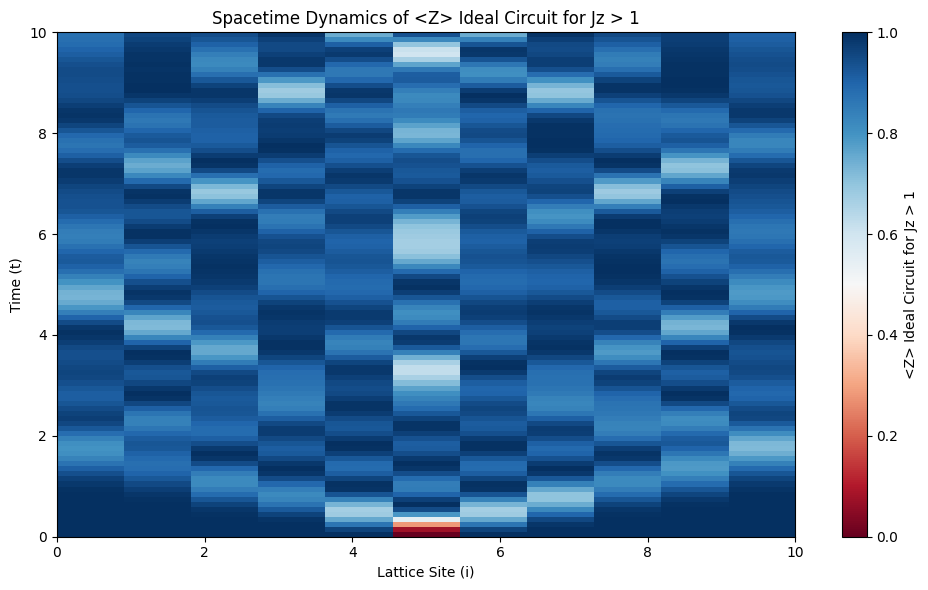

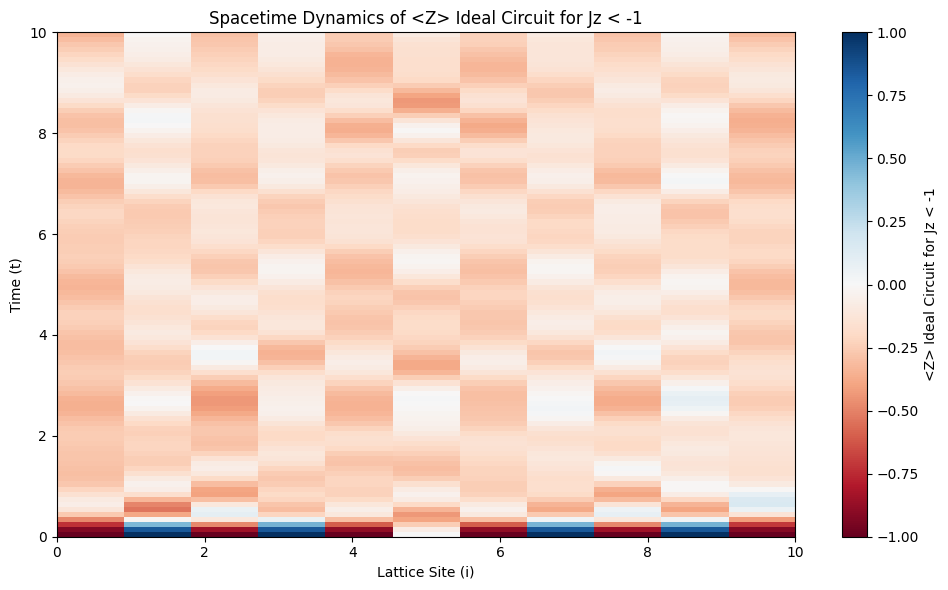

In [ ]:
'''
Creating spacetime heatmaps of expectation value of Z for ferromagnetic and
antiferromagnetic case on ideal quantum circuits
'''

plot_spacetime(Z_ideal, dt=0.1, observable_name="<Z> Ideal Circuit for Jz > 1")
plot_spacetime(Z_ideal2, dt=0.1, observable_name="<Z> Ideal Circuit for Jz < -1")

### 6.3 Classical Exact Simulation

### Overview of the Heatmaps

These plots visualize the mathematically perfect, continuous time evolution of our $L=11$ spin chain. By calculating the exact matrix exponential over 10 seconds ($t=10$), we create a flawless "Answer Key." This allows us to see the pure physics of the wave moving without any of the "blocky" Trotter errors or hardware noise that exist in the quantum circuits.

### Ferromagnetic / Vacuum State ($J_z > 1.0$)
In the first plot, we start with a blank canvas and watch a single ripple spread:
* **The Background:** The system begins in the all_0 state. You can see this as the solid dark blue color across the bottom row, meaning every spin is pointing "up" ($\langle Z \rangle = 1$).
* **The Light Cone:** At $t=0$, we "kick" the center spin (Site 5), dropping its $Z$-value to nearly zero (the red/white spot). As time moves forward, this disturbance spreads outwards in a perfect "V" shape. This "V" represents the quantum speed limit, or the Lieb-Robinson Light Cone [1], showing the maximum speed that information can travel through our simulated universe.
* **Boundary Reflections:** Because our chain is not an infinite loop (open boundaries), the wave hits the "walls" (Site 0 and Site 10) at around $t=5$. You can clearly see the wave bounce off these edges and travel back toward the center, creating an overlapping "echo" pattern in the top half of the graph.

### Antiferromagnetic / Néel State ($J_z < -1.0$)
In the second plot, we change the rules of the interactions and the starting state, which drastically changes how the wave travels:
* **The Checkerboard Background:** The system begins in the neel_10 state. Looking at the bottom row ($t=0$), the colors alternate between dark blue ($+1$) and dark red ($-1$). This is a highly ordered, alternating spin pattern.
* **Scrambling the Order:** When the center spin (Site 5) is kicked, the wave still expands within a "V" shaped light cone. However, instead of a smooth ripple on a blank canvas, the wave disrupts the delicate alternating background.
* **Complex Interference:** As the wave spreads and bounces off the boundaries, it creates a highly complex, criss-crossing checkerboard pattern. This shows how rapidly entanglement and disorder spread through a highly structured initial state.

### Comparison to the Ideal Quantum Circuit
Crucially, these exact classical heatmaps look nearly identical to the outputs of our Ideal Quantum Circuit simulation. The boundaries, the speed of the light cone, and the echo patterns align perfectly. This confirms that our quantum gate sequence (our Trotterized Hamiltonian) is mathematically correct. Moving forward, any blurring or fading we see in the real IBM hardware data can be confidently blamed on physical hardware noise, not a flaw in our circuit design.

In [ ]:
'''
Simulating the classical exact circuit for ferromagnetic state with spins
facing down and antiferromagnetic state. Number of spins, L was kept at 1, and
the circuit was made for dt at 0.1s for 100 steps to match the idea circuit
simulation.
'''

X_exact, Y_exact, Z_exact = classical(L=11, Jz=1.0, state_type='all_0', dt=0.1, n_steps=100)
X_exact2, Y_exact2, Z_exact2 = classical(L=11, Jz=-1.0, state_type='neel_10', dt=0.1, n_steps=100)

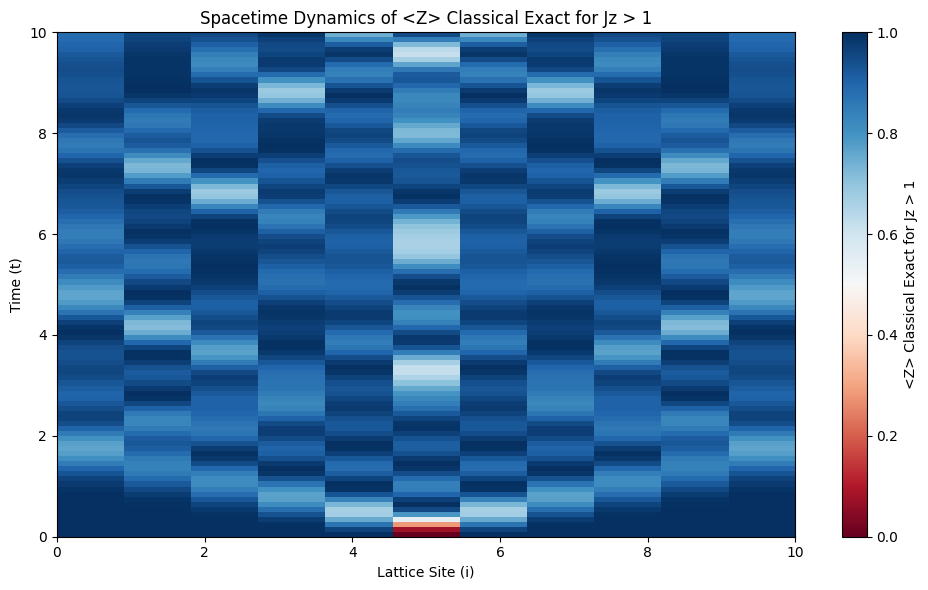

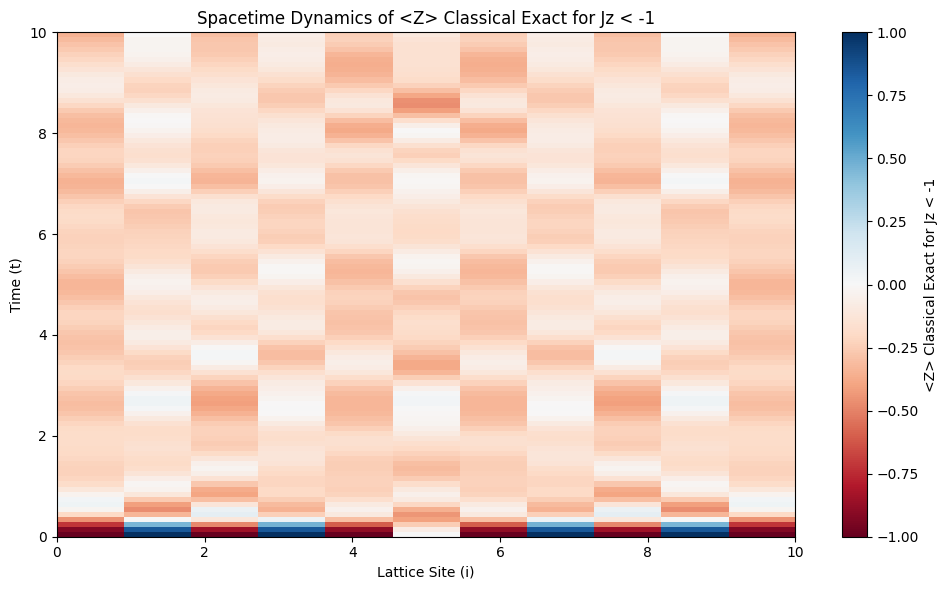

In [ ]:
'''
Creating spacetime heatmaps of expectation value of Z for ferromagnetic and
antiferromagnetic case on classical exact circuits
'''

plot_spacetime(Z_exact, dt=0.1, observable_name="<Z> Classical Exact for Jz > 1")
plot_spacetime(Z_exact2, dt=0.1, observable_name="<Z> Classical Exact for Jz < -1")

### 6.4 Site Comparison

A site-resolved comparison was performed between the classical exact solution and the ideal (noise-free) quantum simulation at a representative lattice site ($i = 5$).

The time evolution of $\langle Z_i(t) \rangle$ shows very close agreement between the two methods for both regimes ($J_z > 1$ and $J_z < -1$). The oscillatory behaviour and overall structure are well reproduced by the quantum circuit.

Small deviations become more noticeable at later times. This occurs because the Suzuki–Trotter decomposition introduces a discretisation error at each timestep, which accumulates as the system evolves. As a result, longer evolution times lead to a gradual divergence between the ideal circuit and the exact solution.

Despite this, the strong agreement at early and intermediate times demonstrates that the Trotterised quantum circuit accurately captures the essential dynamics of the system in the absence of noise.

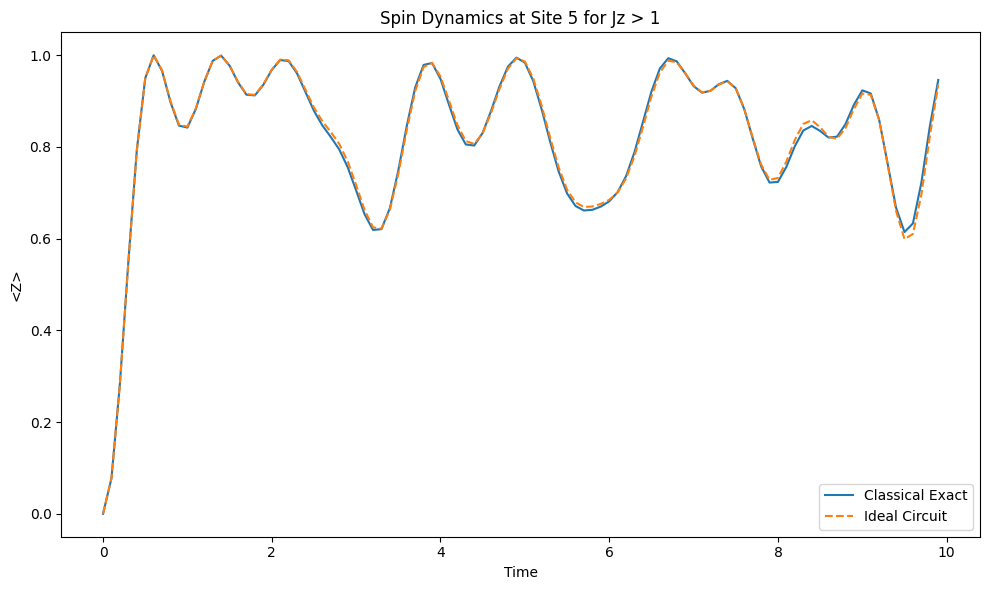

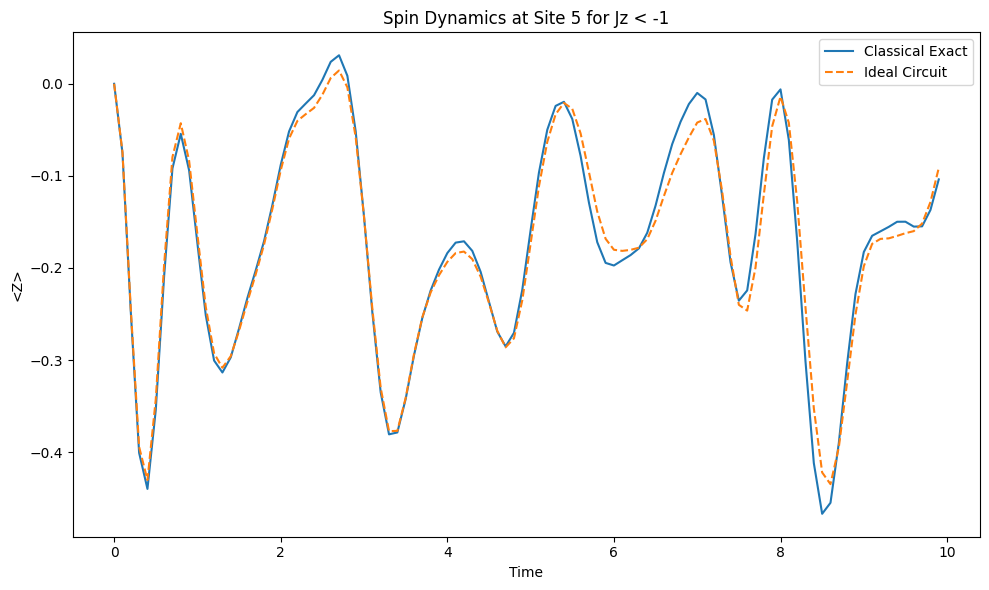

In [ ]:
# Perform site-resolved comparison of ⟨Z_i(t)⟩ between classical exact
# and ideal quantum simulations at site i = 5
# Results are shown for both interaction regimes (Jz > 1 and Jz < -1),
# allowing validation of the Trotterised quantum evolution against
# the exact dynamics. Small deviations are expected due to finite timestep (dt = 0.1)
plot_site_comparison(Z_exact, Z_ideal, X_exact , dt=0.1, site=5, name="Jz > 1", plotno=2, plot2="Ideal Circuit")
plot_site_comparison(Z_exact2, Z_ideal2, X_exact, dt=0.1, site=5, name="Jz < -1", plotno=2, plot2="Ideal Circuit")

### 6.5 Error Heatmap

Before introducing real-world hardware noise, we needed to isolate the errors caused purely by our algorithm's design. To do this, we compared our exact, continuous classical simulation against an "ideal" (zero-noise) quantum circuit. The only difference between these two models is Trotterization [2], the mathematical process where the quantum circuit is forced to chop smooth, continuous time into discrete, blocky steps.

To quantify this algorithmic discrepancy, we calculated the absolute error at each lattice site using the following formula:

$$|\langle Z \rangle_{\text{exact}} - \langle Z \rangle_{\text{ideal}}|$$

We plotted these calculated errors as heatmaps for both the ferromagnetic ($J_z > 1.0$) and antiferromagnetic ($J_z < -1.0$) setups. These heatmaps reveal two specific algorithmic trends:

* **Errors decrease over time:** In both plots, the brightest error patches appear early on (between $t = 0$ and $t = 2$). As the simulation steps further forward, the error fades into dark purples. This happens because we are measuring the local spin at specific sites. Early on, the initial states are highly structured, so tiny Trotterization errors create large, visible differences. However, as time passes, the system naturally scrambles and spreads information out. Because both the exact and ideal models are scrambling the local measurements toward zero, the absolute difference between them naturally shrinks.
* **The boundaries struggle more than the bulk:** The errors do not distribute evenly. In the antiferromagnetic setup, there are yellow and orange error spikes on the far left and right edges (Sites 0 and 10), while the center of the chain stays relatively accurate. This is due to Open Boundary Conditions. The spins at the physical ends of the chain are missing a neighbor on one side. This lack of symmetry means the discrete Trotter gates do not overlap and cancel out errors at the edges in the same smooth way they do in the "bulk" (the middle) of the chain.

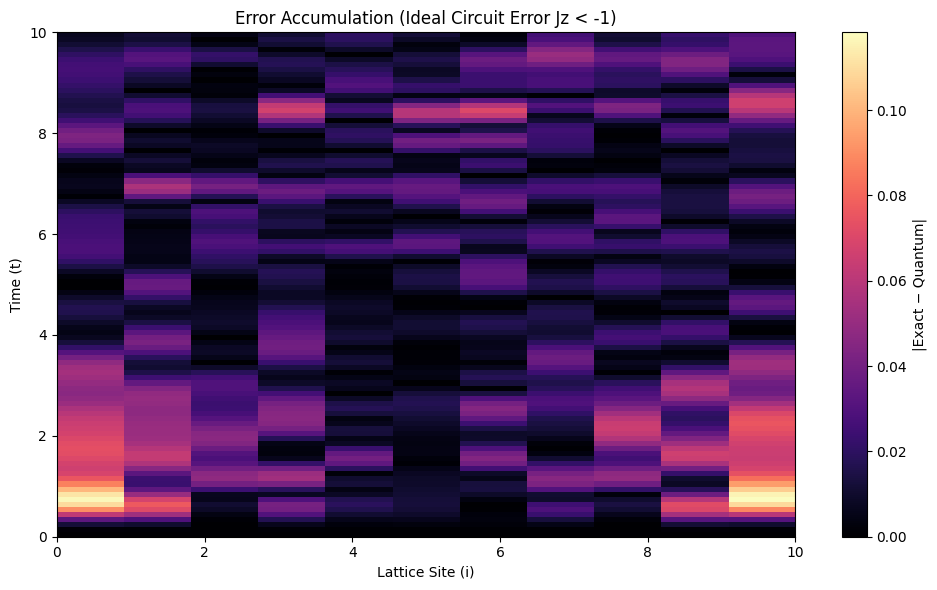

In [ ]:
'''
Plotting error heatmap for both ferromagnetic and antiferromagnetic cases to
visualize the actual comparative inconsitencies between ideal quantum and
classical exact circuits.
'''

plot_error_heatmap(Z_exact, Z_ideal, dt=0.1, name="Ideal Circuit Error Jz > 1")
plot_error_heatmap(Z_exact2, Z_ideal2, dt=0.1, name="Ideal Circuit Error Jz < -1")

### 6.6 Fourier analysis

To examine the dynamics in momentum-frequency space, a two-dimensional Fourier transform was applied to the space-time data for the obserables. This is also suggested in the project brief as a useful way to analyse the dynamics beyond the real-space heatmaps. For a signal $S(j,t)$, where $j$ labels lattice site and $t$ labels time, the transform can be written as

$$
\tilde{S}(k,\omega)=\sum_j \sum_t S(j,t)\,e^{-i(kj-\omega t)},
$$

where $k$ is the momentum variable and $\omega$ is the frequency variable. This converts the data from a space-time description into a momentum-frequency description, making the dominant propagation modes easier to identify.

The spectra were plotted on a logarithmic scale using

$$
M(k,\omega)=\log\!\left(|\tilde{S}(k,\omega)|+\epsilon\right),
$$

where $\epsilon$ is a small constant added to avoid taking the logarithm of zero. The Fourier components were also shifted using `fftshift`, which rearranges them into ascending order and places the low-momentum and low-frequency region in the centre of the plot. The workshop material notes that this ordering is more useful for physical interpretation than the default FFT output.

For the positive-$J_z$ case, the classical exact and ideal-circuit Fourier plots show the same broad structure. In both plots, the strongest spectral weight is concentrated in the same low-frequency region, and the main bright bands and darker features appear in similar positions across momentum space. This indicates that the dominant propagation modes are the same in both methods.

A similar result is seen for the negative-$J_z$ case. The classical exact and ideal-circuit spectra again show the same overall pattern, with the main regions of enhanced and suppressed spectral weight appearing in comparable parts of the $(k,\omega)$ plane. Although the detailed colour pattern is not identical, the broad spectral structure remains consistent.

Although the classical exact and ideal-circuit Fourier plots have the same overall dispersion shape, the detailed colour pattern is not identical. This is because the broad shape of the spectrum is determined by the dominant propagation modes of the system, so the main bright bands and dark regions appear in the same places when both methods reproduce the same underlying physics. However, the exact colour of each pixel depends on the intensity of the corresponding Fourier component, and this is more sensitive to numerical details. Small errors from the Suzuki--Trotter approximation, finite timestep, limited time sampling, and circuit discretisation can redistribute spectral weight slightly between nearby $(k,\omega)$ points without changing the main spectral structure. As a result, the overall shape remains the same, while the detailed intensity pattern becomes different. The project brief also emphasises that Suzuki--Trotter evolution involves balancing timestep size against circuit length, and that the accuracy depends on the size and number of Trotter steps.

This difference is made more visible because the spectra are plotted on a logarithmic scale. On a log-intensity plot, even relatively small changes in Fourier amplitude can produce noticeable colour differences. The plots therefore look different in their fine texture, even though their dominant spectral features still agree. In this sense, the matching shape is the more important result, because it shows that both methods capture the same propagation physics, while the colour differences mainly reflect approximation error rather than a change in the underlying dynamics.

To make the weaker features easier to see, the $k=0$ and $\omega=0$ components were removed before plotting. These central components have much larger intensity than the rest of the spectrum and would otherwise dominate the colour scale. If they were left in, the weaker non-trivial features would be much harder to distinguish, and the two transforms would appear much more visually similar simply because both would be dominated by the same very large central contributions.

Overall, the Fourier analysis shows that the classical exact and ideal quantum results have the same broad dispersion structure, while the remaining differences are mainly in the detailed log intensity rather than in the position or shape of the main spectral features[9].

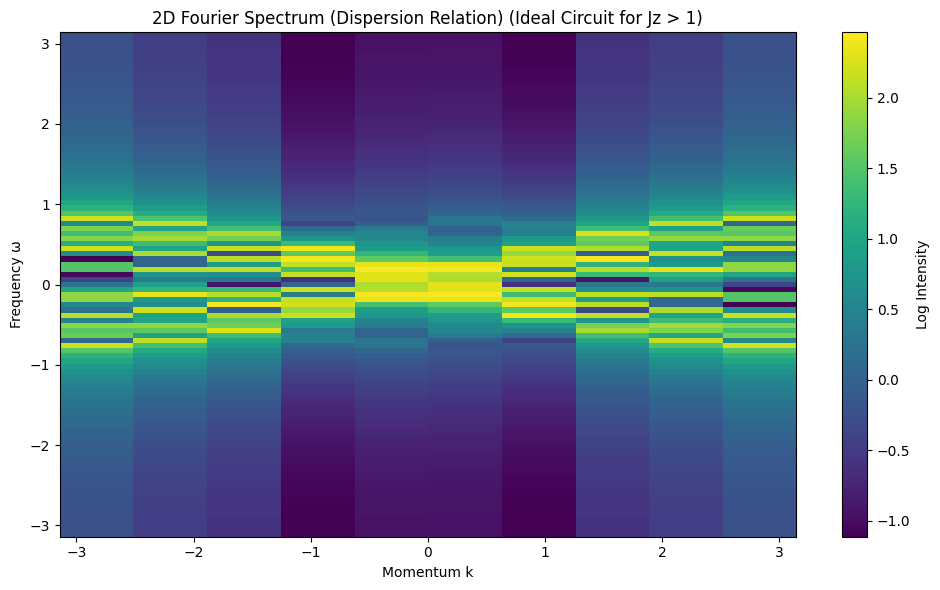

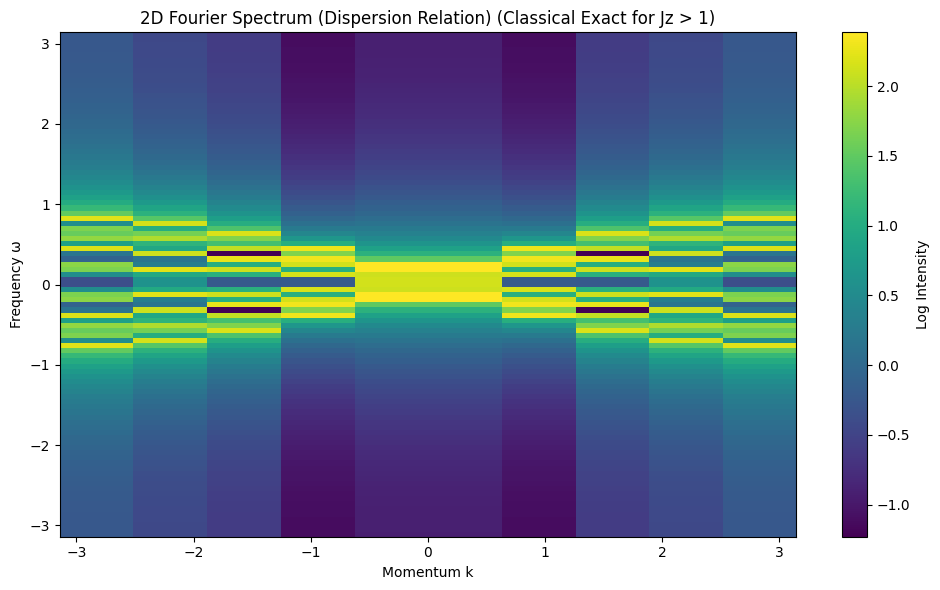

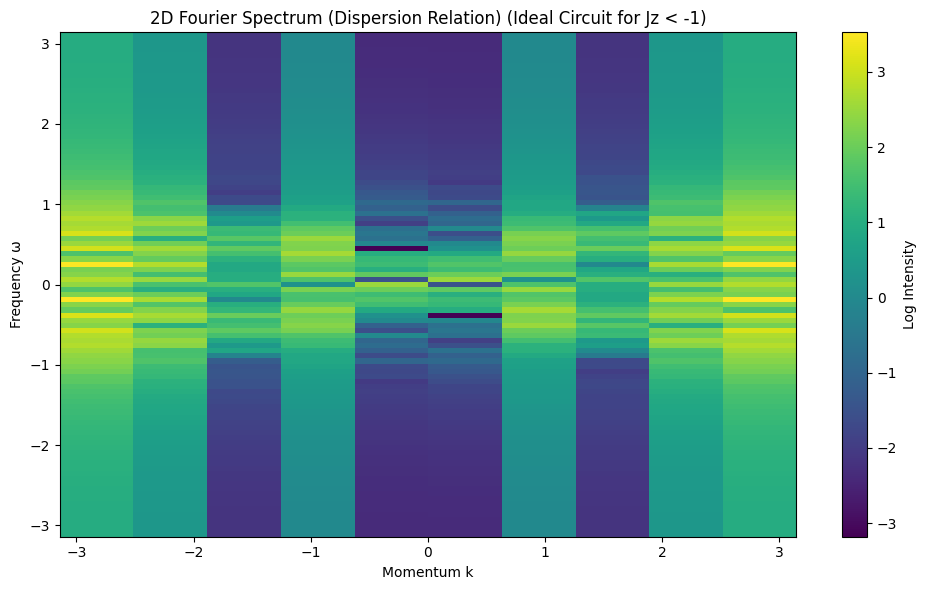

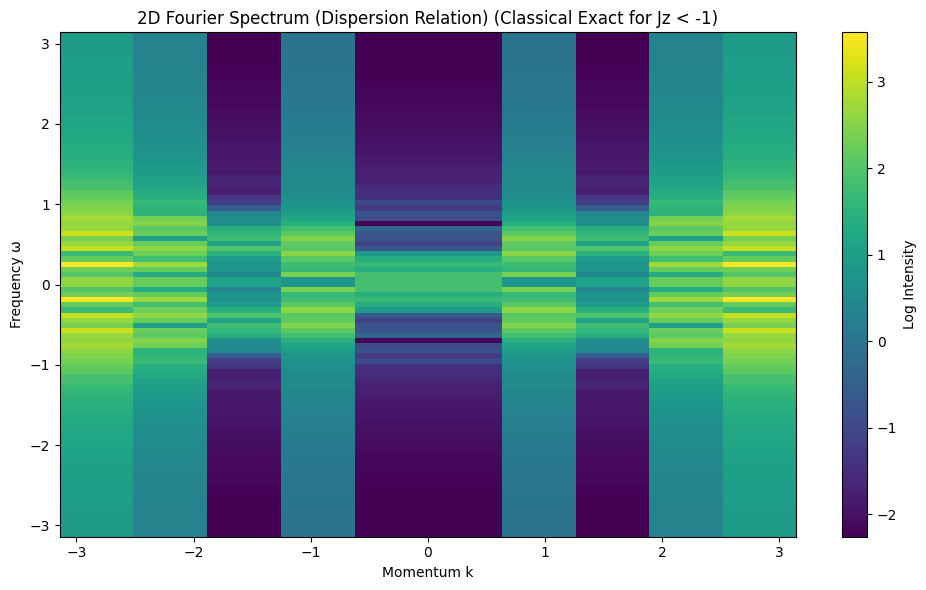

In [ ]:
# Fourier plot for ideal circuit, positive-Jz case
plot_fourier_transform(Z_ideal, name="Ideal Circuit for Jz > 1")
# Fourier plot for exact classical result, positive-Jz case
plot_fourier_transform(Z_exact,  name="Classical Exact for Jz > 1")
# Fourier plot for ideal circuit, negative-Jz case
plot_fourier_transform(Z_ideal2, name="Ideal Circuit for Jz < -1")
# Fourier plot for exact classical result, negative-Jz case
plot_fourier_transform(Z_exact2,  name="Classical Exact for Jz < -1")

### 6.7 Trotter Circuit Accuracy

### 6.7.1 What We're Testing

As we explained in Section 3.2, the Trotter method works by pretending the even and odd bond groups are independent for a small time dt. They're not, so this introduces a small error at every step.

Before running anything on a real quantum computer, we need to answer a simple question: **how much of what we see is real physics, and how much is fake noise from the Trotter approximation?**

To find out, we compared two things:

- **Exact classical simulation** — the mathematically perfect answer, computed on a normal computer.
- **Ideal quantum simulation** — our Trotter circuit running on a perfect, noise-free simulated quantum computer (`es_ideal`).

Any difference between the two is **purely Trotter error** — no hardware noise, no measurement randomness, just the cost of chopping time into discrete steps.

We measured this difference using Mean Squared Error across all qubits and all time steps:

$$MSE = \frac{1}{N} \sum (\langle Z_i(t) \rangle_{exact} - \langle Z_i(t) \rangle_{ideal})^2$$

Then we repeated this for a range of dt values (from very small to fairly large) to see how the error grows.


### 6.7.2 What We Found

The log-log plot tells a clear story in two parts:

**The straight line region (small dt).** For small time steps, the error follows a clean power law: Error ∝ dt². On a log-log plot, power laws show up as straight lines, and the slope tells you the exponent. Our data tracks the dashed O(dt²) reference line almost perfectly. This confirms the theory: first-order Trotter error scales as dt squared, exactly as expected.

**The curve at large dt.** Around dt ≈ 0.1 and above, the error starts bending upward away from the straight line. This happens because dt² is only the *leading* error term. There are also dt³, dt⁴, and higher terms that we normally ignore because they're tiny. But when dt gets big enough, those extra terms stop being tiny and start piling up andnthe approximation breaks down.

This pattern looks the same for both the ferromagnetic (Jz = 1) and antiferromagnetic (Jz = −1) cases.

**The practical tradeoff.** In theory, you fix this by making dt as small as possible. But smaller dt means more Trotter steps to reach the same total time which means a deeper circuit. On a real quantum computer, deeper circuits get destroyed by hardware noise (decoherence, gate errors).

- **dt too large** → Trotter error dominates (the approximation is too rough).
- **dt too small** → circuit is too deep and hardware noise dominates.

We have to pick a middle ground. Something like dt = 0.1 keeps the circuit short enough for real hardware to handle, while accepting a small but manageable drift from the exact answer.

In [ ]:
"""
Empirically verifies the Trotter error scaling by comparing quantum circuit
results against a classical exact solver across a range of step sizes.
Any deviation from a straight line of MSE vs dt graph indicates higher
order effects or noise.
"""

def trotter_accuracy_study(L, Jz, state_type, t_max, estimator, name):

    # Sample 8 step sizes logarithmically from dt≈0.01 to dt≈0.5
    # Log spacing is used here to make each point informative
    dt_values = np.logspace(-2, -0.3, 8)
    errors = []

    for dt in dt_values:

        # Round up to the nearest integer number of steps, then recompute dt so that the simulation hits t_max exactly in eacg run
        num_steps = int(np.ceil(t_max / dt))
        actual_dt = t_max / num_steps

        # Z expectation value only of classical exact
        Z_exact = classical(L, Jz, state_type, actual_dt, num_steps)[2]

        # Z expectation value only of ideal quantum circuit
        Z_ideal = quantum_dynamics(L, Jz, state_type, actual_dt, num_steps, estimator, backend=None)[2]

        # MSE over all sites and all time steps collapses the full array into a single scalar error metric per dt value
        mse = np.mean((Z_exact - Z_ideal)**2)
        errors.append(mse)

    plt.figure(figsize=(10,6))

    # Log-log plot makes dt appear as straight line with a slope
    plt.loglog(dt_values, errors, "o-", label="Trotter Error")

    # A reference O(dt²) line to compare it to our measured slope
    # Matching this line exactly would theoretically make our measured line a second-order trotter
    plt.loglog(dt_values, errors[0]*(dt_values/dt_values[0])**2, "--", label="O(dt^2) slope")

    plt.xlabel("Trotter step size (dt)")
    plt.ylabel("Mean Squared Error")
    plt.title(f"Trotter Accuracy Study {name}")
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

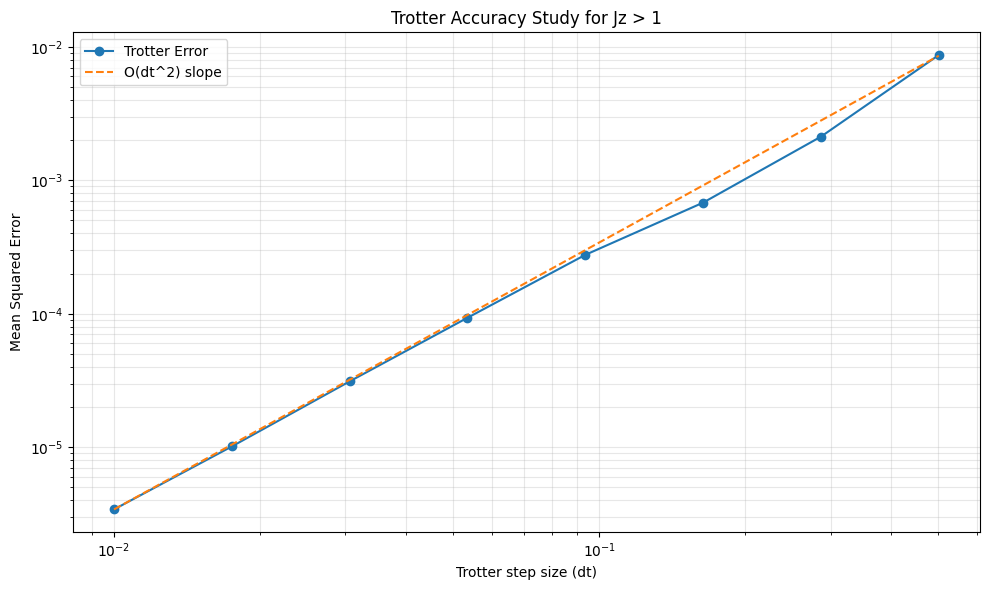

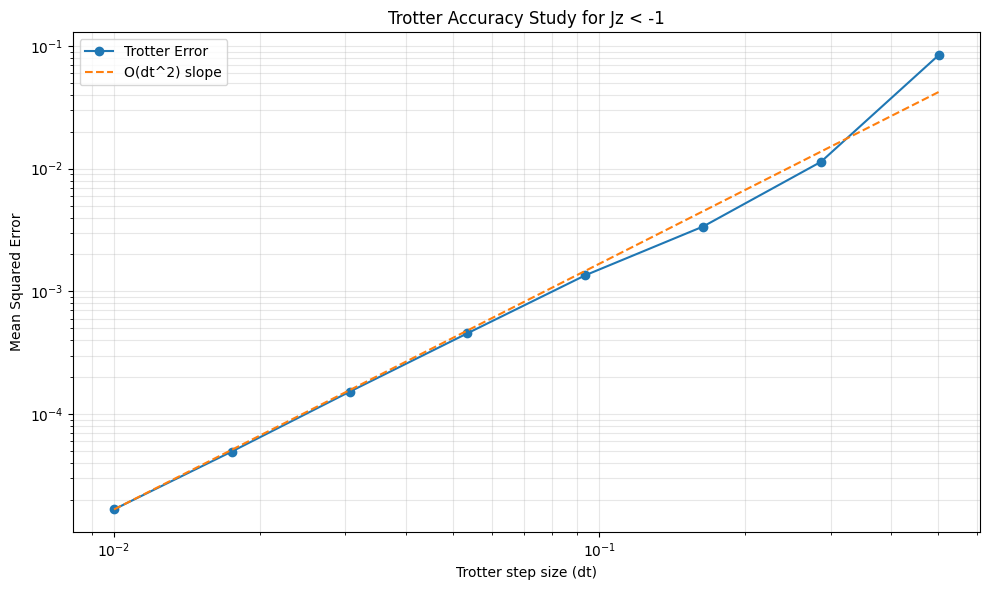

In [ ]:
'''
Plotting the log-log MSE vs dt graph for both ferromagnetic and
antiferromagnetic cases to visualize trotter circuit accuracy while keeping the
conditions similar to our previous simulations.
'''

trotter_accuracy_study(L=11, Jz=1.0, state_type="all_0", t_max=1.0, estimator=es_ideal, name="for Jz > 1")
trotter_accuracy_study(L=11, Jz=-1.0, state_type="neel_10", t_max=1.0, estimator=es_ideal, name="for Jz < -1")

### 6.8 Noisy Circuit Simulation

### 6.8.1 Advantages

Running on a real IBM quantum computer costs time and credits, so we don't want to do it without having some idea of how it works. Hence, we first simulate the exact conditions of a real device in this case, `ibm_marrakesh`  using a noisy simulator that behaves like the real machine. Qiskit lets us pull the noise directly from ibm_marrakesh.

We matched all the parameters to what we planned to use on the real device: L = 11 qubits, dt = 0.1, 20 time steps (total evolution time t = 2.0), and first-order Trotter. The dt = 0.1 choice comes from the tradeoff we identified in Section 6.8.

The goal is simple: **figure out which configurations are worth spending real quantum hardware time on.**


### 6.8.2 Noise Spacetime Heatmap

**Ferromagnetic case (Jz > 1.0, all-zero initial state).** The heatmap shows a lightcone pattern spreading outward from the centre of the chain. At t = 0, most qubits start in the |0⟩ state (dark blue, ⟨Z⟩ ≈ +1), with a flipped spin near site 5 (red/white, ⟨Z⟩ near −1). As time increases, the pattern spreads outward in a cone shape exactly the signature of information propagating through the spin chain at some speed. Even with realistic noise, the structure is clearly visible through the full evolution. The signal degrades gradually toward later times (colours washing out slightly), but the physics remains readable.

**Antiferromagnetic case (Jz < −1.0, Néel initial state).** The picture is very different. The Néel state starts with a strong alternating pattern at t = 0 (sharp red/blue stripes), but by t ≈ 0.5 the entire heatmap has washed out to a near-uniform pale colour (⟨Z⟩ ≈ 0). The signal is essentially destroyed. This happens because the antiferromagnetic Néel state is much more sensitive to noise because every spin(Néel state) has to be the exact opposite of the one next to it, and if noise changes even one spin, that effect transfers onto its neighbors and the whole alternating pattern falls apart.

In [ ]:
'''
Simualte the noise aware quantum circuit by mirroring the backend from
ibm_marrakesh which proved to be processor used for the real IBM hardware run.
This was done for both ferromagnetic and antiferromagnetic cases to choose one
for our final run in the allocated time.
'''

es_noisy, backend = noisy_estimator(backend_name="ibm_marrakesh")

# The parameters were changed later with respect to the real IBM hardware run done later
# Parameters were chosen to find a balance between runtime and accuracy of the circuit
# The major change here for previous simulations was making the steps lower to 20 thus bringing total time to 2s
X_noisy, Y_noisy, Z_noisy = quantum_dynamics(L=11, Jz=1.0, state_type='all_0', dt=0.1, steps=20, estimator=es_noisy, backend=backend)
X_noisy2, Y_noisy2, Z_noisy2 = quantum_dynamics(L=11, Jz=-1.0, state_type='neel_10', dt=0.1, steps=20, estimator=es_noisy, backend=backend)

qiskit_runtime_service.__init__:WARNING:2026-03-18 18:03:50,844: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-03-18 18:03:50,845: Using instance: open-instance, plan: open


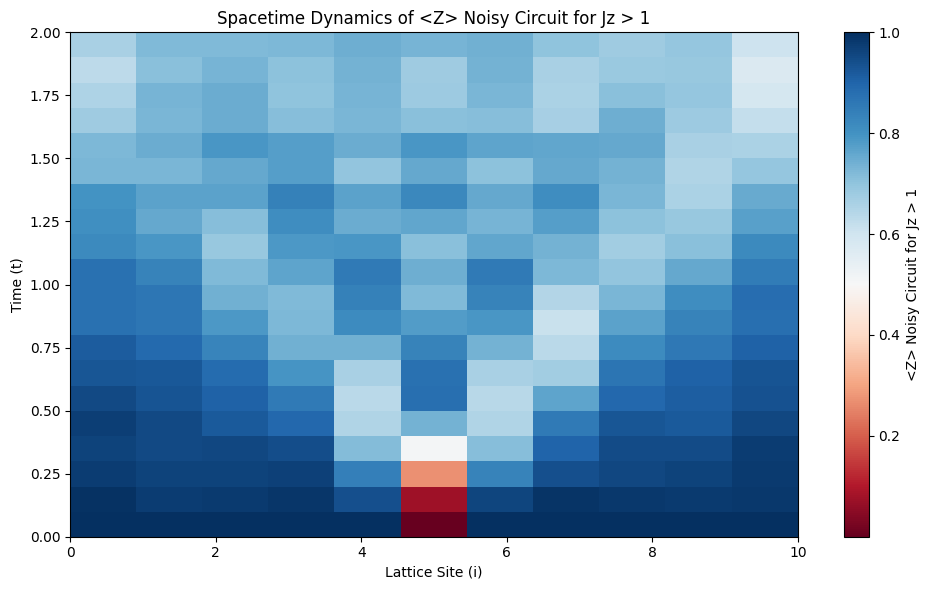

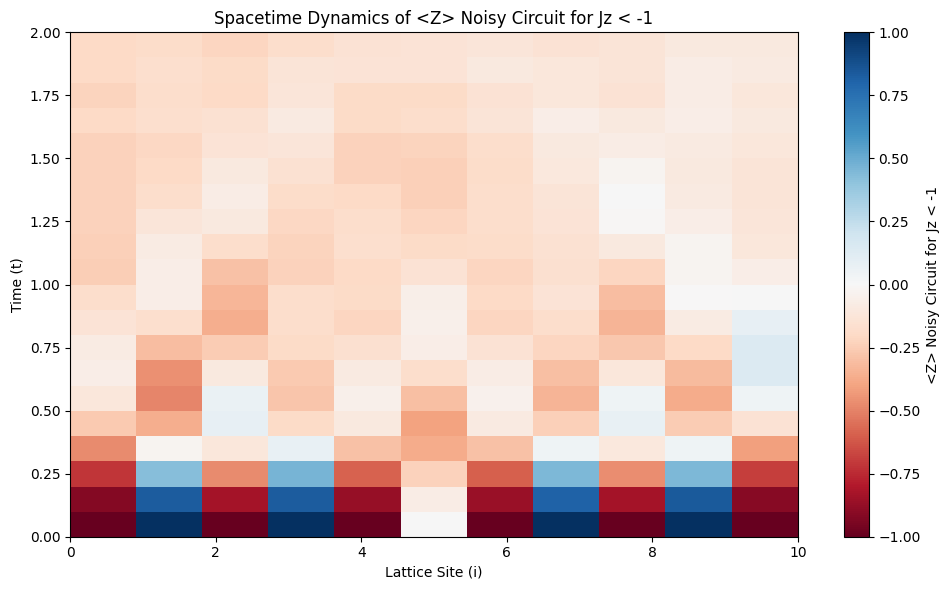

In [ ]:
'''
Creating spacetime heatmaps of expectation value of Z for ferromagnetic and
antiferromagnetic case on noisy quantum circuit of ibm_marrakesh
'''

plot_spacetime(Z_noisy, dt=0.1, observable_name="<Z> Noisy Circuit for Jz > 1")
plot_spacetime(Z_noisy2, dt=0.1, observable_name="<Z> Noisy Circuit for Jz < -1")

### 6.8.3 Noise Error Heatmap

Before spending resources on the actual real-world quantum computer (`ibm_marrakesh`), we needed to measure exactly how much the machine's natural hardware noise would blur our results. To do this, we ran a perfect, noise-free classical simulation using the exact same settings we planned to use on the real device: 11 qubits ($L=11$), a time step of 0.1 ($dt=0.1$), and 20 total time steps.

We then compared this perfect baseline to a simulation that artificially included noise. We calculated the absolute error at every single lattice site using this formula:

$$|\langle Z \rangle_{\text{exact}} - \langle Z \rangle_{\text{noisy}}|$$

We plotted these calculated errors onto heatmaps for both of our test configurations: the ferromagnetic setup ($J_z > 1.0$) and the antiferromagnetic setup ($J_z < -1.0$).

Looking at the heatmaps, a few crucial trends stand out that directly informed our hardware strategy:

* **Errors pile up over time:** In both configurations, the simulation starts perfectly at the bottom of the graph ($t=0$), meaning the error is practically zero. However, as the simulation steps forward and the quantum circuit gets deeper, the simulated gate glitches and the natural loss of the quantum state (decoherence) start to add up. This cumulative effect causes the error to steadily grow, reaching its absolute highest values at the very end of the simulation ($t \to 2.0$).
* **The Ferromagnetic setup is tough:** When starting with all spins pointing the same way, the error mostly accumulates within the boundaries of the spreading "lightcone." Even with this noise, the core physical pattern—the spreading wave—remains structurally stable and easy to read.
* **The Antiferromagnetic setup is fragile (Néel State):** When starting with the spins in a strictly alternating up-and-down pattern, the system is far more delicate. Because this state relies on highly sensitive correlations between neighboring spins, it is easily ruined by "depolarizing noise." The noise rapidly scrambles these local interactions, destroying the alternating pattern and completely washing out any meaningful physical signal very early in the simulation.

#### Our Hardware Decision

Because of this high sensitivity to destructive errors, we concluded that the antiferromagnetic setup would not yield readable results on the real quantum device. Therefore, we decided to run **only the ferromagnetic case** on the actual IBM hardware, as its underlying physics is robust enough to survive `ibm_marrakesh`'s real-world noise profile.

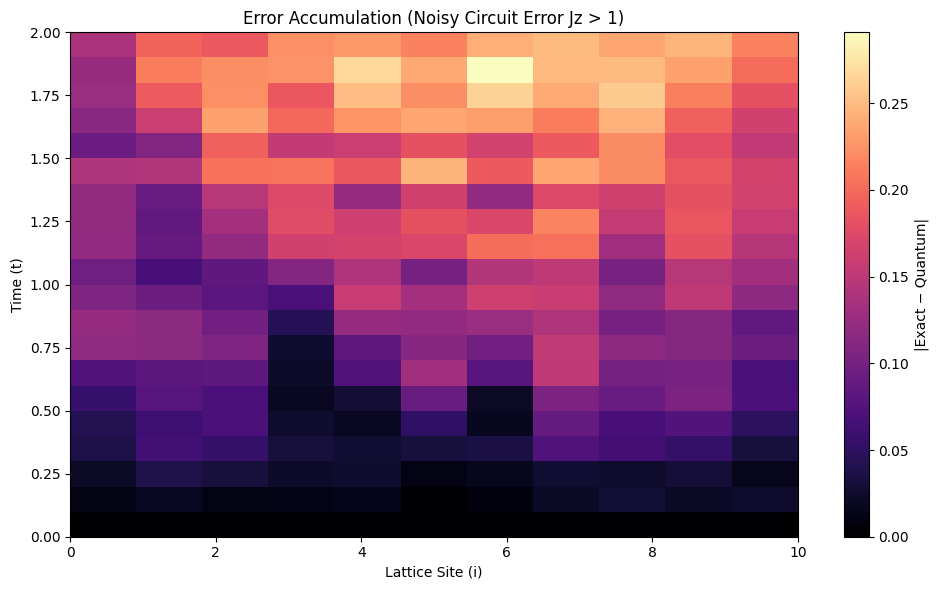

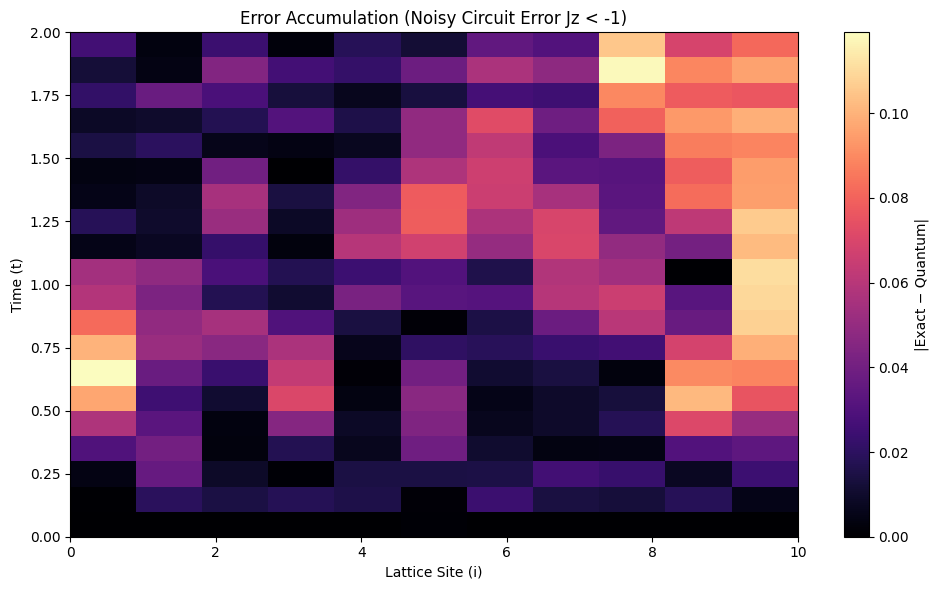

In [ ]:
'''
Plotting error heatmap for both ferromagnetic and antiferromagnetic cases to
visualize the actual comparative inconsitencies between noisy circuits and
classical exact circuits.
'''

# Two new simulation runs were done for the classical exact to match the conditions of noisy and IBM simulations
# This would keep the comaprison fair
X_exact3, Y_exact3, Z_exact3 = classical(L=11, Jz=1.0, state_type='all_0', dt=0.1, n_steps=20)
X_exact4, Y_exact4, Z_exact4 = classical(L=11, Jz=-1.0, state_type='neel_10', dt=0.1, n_steps=20)

plot_error_heatmap(Z_exact3, Z_noisy, dt=0.1, name="Noisy Circuit Error Jz > 1")
plot_error_heatmap(Z_exact4, Z_noisy2, dt=0.1, name="Noisy Circuit Error Jz < -1")

## 7. IBM Hardware Run

### 7.1 Execution

### Initial Attempts and Job Batching

Our initial hardware execution strategy involved submitting individual circuits for each time step in the simulation, starting with a 5-site lattice ($L=5$). We observed that handling time evolution this way was highly inefficient, as the program had to wait in the IBM cloud queue for every single frame of the simulation. To resolve this, we modified the codebase to package all temporal circuits into a single "batch". This allowed us to submit the entire experiment as a single job, drastically reducing queue wait times.

### Error Mitigation and Runtime Trade-offs

Our early batched runs utilized Resilience Level 1, which applies Twirled Readout Error Extinction **(TREX)** strictly for measurement mitigation. However, this proved insufficient for deeper Trotter circuits as the system lost coherence.

To combat this, we elevated the error mitigation to Resilience Level 2, which introduces Zero Noise Extrapolation **(ZNE)** alongside TREX to mitigate gate-level errors. The ZNE method mathematically extrapolates the zero-noise limit, but requires the physical QPU to run intentionally "stretched" and noisier versions of the circuit behind the scenes. Consequently, our hardware runtimes spiked significantly, jumping from around 4 to 7 minutes to well over 25 minutes.

### Iterative Parameter Tuning
To navigate these runtime penalties, we systematically iterated on our input parameters to find a balance between physical accuracy and realistic execution limits. Throughout all experiments, we maintained a consistent baseline of 4000 shots per circuit to ensure stable statistical sampling:

* We initially attempted a longer 100-step simulation ($dt=0.1, t_{max}=9.9$) at Level 1, but the physical coherence loss was too severe.
* Upon switching to Level 2 mitigation for better accuracy, the system struggled with the increased circuit depth. Attempting a 50-step simulation ($dt=0.1$) resulted in execution times exceeding 25 minutes, forcing us to manually cancel the jobs before completion.
* To strictly constrain the QPU compute time while maintaining the required Level 2 mitigation, we scaled the temporal bounds back to 20 time steps at $dt=0.1$ ($t_{max}=1.9$). This successfully brought total execution times down to a manageable 9 to 10 minutes, with roughly 1.5 minutes of raw QPU execution time.
* Having established a stable and efficient temporal window, we then shifted our focus to scaling the physical system size. We increased the lattice count from $L=5$ to $L=6$, and ultimately pushed the hardware to simulate an $L=11$ spin chain.

Because the heavy compute cost of Level 2 mitigation rapidly depleted our allocated IBM Quantum free time, we had to cycle through multiple API keys to secure enough compute quota to complete the scaled experiments. Furthermore, rather than targeting specific physical backend QPU's, we exclusively utilized Qiskit's `least_busy` routing to minimize queue delays.

### Final Hardware Execution Parameters
Following the iterative tuning of our mitigation levels, physical time bounds, and lattice size, our final scaled hardware execution was successfully submitted using the following configuration:

* **Lattice Size ($L$):** 11
* **Time Step ($dt$):** 0.1
* **Maximum Time ($t_{max}$):** 1.9
* **Coupling Strength ($J_z$):** 1.0
* **Shots:** 4000
* **Resilience Level:** 2
* **Circuit Generator:** `hardware_circuit`

In [ ]:
def run_ibm_hardware(L, Jz, t_max, dt, circuit_function):
    # Calculate the exact time intervals we need to simulate
    time_steps = np.arange(0, t_max + dt, dt)

    # CONNECT TO IBM
    # Automatically find and connect to the least busy physical quantum computer
    service = QiskitRuntimeService()
    backend = service.backend("ibm_marrakesh")
    print(f"Targeting physical backend: {backend.name}")

    # SET UP NOISE SUPPRESSION
    # Configure hardware error mitigation to protect the quantum states from decoherence
    options = EstimatorOptions()
    options.resilience_level = 2
    options.dynamical_decoupling.enable = True
    options.dynamical_decoupling.sequence_type = "XY4"
    options.default_shots = 4000
    estimator = EstimatorV2(mode=backend, options=options)

    # DEFINE PHYSICAL OBSERVABLES
    # Create the mathematical operators to measure the Z-axis spin at every site
    observables = []
    for i in range(L):
        obs_z = ['I'] * L
        obs_z[i] = 'Z'
        observables.append(SparsePauliOp("".join(obs_z)))

    # Initialize the empty matrix to hold our spacetime data
    data_Z = np.zeros((len(time_steps), L))

    # HARDWARE OPTIMIZATION ENGINE
    # Initialize the compiler to translate our theoretical gates into the hardware's native layout
    pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

    # BATCH COMPILATION
    # Loop through time to compile and package each circuit with its measurement instructions
    print(f"Compiling {len(time_steps)} circuits for batch submission...")
    circuit_bundles = []
    for step_idx, t in enumerate(time_steps):
        qc = circuit_function(L=L, Jz=Jz, time=t, dt=dt)

        # Transpile the circuit and map the observables to the specific physical qubits used
        isa_circuit = pm.run(qc)
        isa_observables = [ob.apply_layout(isa_circuit.layout) for ob in observables]

        circuit_bundles.append((isa_circuit, isa_observables))

    # BATCH EXECUTION
    # Send all bundled circuits to the IBM queue as one single job to reduce wait times
    job = estimator.run(circuit_bundles)
    print(f"Batch Job ID: {job.job_id()}")

    # Wait for the backend to finish processing the entire timeline
    all_results = job.result()

    # UNPACK RESULTS
    # Extract the expectation values from the returned batch and organize them into the matrix
    for step_idx in range(len(time_steps)):
        evs = all_results[step_idx].data.evs
        for site in range(L):
            data_Z[step_idx, site] = evs[site]

    print("\nHardware execution complete!")
    return data_Z

def hardware_circuit(L, Jz, time, dt):

    # Calculate the required Trotter steps for the target physical time
    steps = int(time / dt)

    H = XXZ_hamil(L, Jz)

    ini = prepare_initial_state(L, "all_0")

    evo = trotter_circuit(H, Jz, dt, steps)

    # Combine the initial state preparation with the time evolution gates
    qc = ini.compose(evo)

    return qc

### 7.2 Results

The IBM hardware results follow the same trend as the classical exact curve at initial times from 0 to 0.45 seconds.At the beginning, the device can work similarly to the classical experiment and ideal quantum circuit.

As time increases, the agreement becomes weaker. At higher times, the hardware curve becomes more irregular and shows larger fluctuations compared with the classical exact result. This is most noticeable towards the end of the evolution, where the data are less smooth and less stable.

This behaviour is consistent with the accumulation of noise during the simulation. Longer evolution times require deeper circuits and more gate operations, so errors build up as the circuit becomes longer. As a result, the signal amplitude becomes suppressed relative to the classical exact result, and the final part of the curve shows visible irregularities. The noisy simulation shows the same general damping effect, while the real hardware result also contains additional fluctuations caused by device noise.

These late-time deviations are therefore not surprising. They indicate that the real device can still reproduce the correct dynamics at short times, but that the accuracy decreases as the effects of noise become stronger. Gate errors, decoherence, and readout noise all contribute to this loss of accuracy.

Overall, the results show that the IBM hardware is able to capture the main physical trend at short times, but at higher times accumulated noise suppresses the amplitude and introduces irregular behaviour. The main dynamics remain visible, although the quality of the result becomes worse as the evolution time increases[11].

In [ ]:
# Run the circuit on IBM hardware
Z_hardware = run_ibm_hardware(L=11, Jz=1.0, t_max = 1.9 , dt = 0.1, circuit_function=hardware_circuit)

qiskit_runtime_service.__init__:WARNING:2026-03-18 17:47:37,158: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-03-18 17:47:37,159: Using instance: open-instance, plan: open


Targeting physical backend: ibm_marrakesh
Compiling 20 circuits for batch submission...
Batch Job ID: d6teaeqtnsts73er05b0

Hardware execution complete!


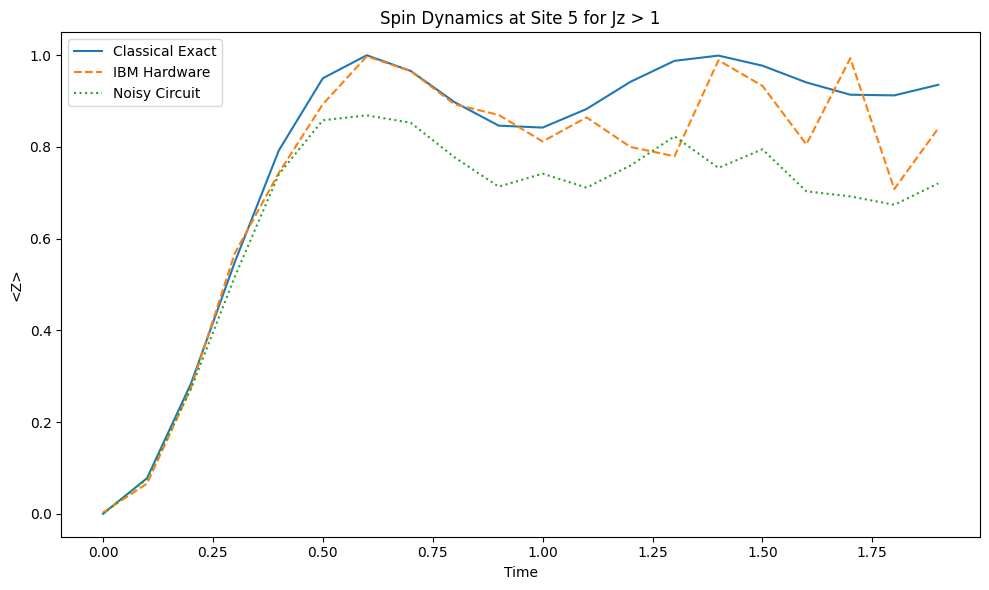

In [ ]:
# Compare exact, noisy, and hardware results at site 5
plot_site_comparison(Z_exact3, Z_hardware, Z_noisy, dt=0.1, site=5, name="Jz > 1", plotno=3, plot2="IBM Hardware")

In [ ]:
# IBM QUANTUM ACCOUNT SETUP (public version)
# Keep API credentials outside the notebook.
import os

ibm_token = os.getenv("IBM_QUANTUM_TOKEN")
if not ibm_token:
    raise RuntimeError("Set the IBM_QUANTUM_TOKEN environment variable before running this cell.")

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=ibm_token,
    set_as_default=True,
    overwrite=True
)

print("IBM Quantum credentials configured from environment variable.")


## 8. Discussion

The results obtained in this project demonstrate that Trotterized quantum circuits provide a powerful and physically meaningful approach to simulating the dynamics of interacting quantum many-body systems. By comparing classical exact simulations, ideal quantum circuit simulations and noisy implementations, we are able to systematically evaluate both the accuracy and practical limitations of current quantum computing appraoches.

A key result of this study is the strong agreement between the classical exact simulation and the ideal quantum circuit simulation. The spacetime plots for ⟨Z⟩ clearly show that the propagation of spin excitations is captured accurately by the quantum circuit, with only minor deviations. Quantitatively, the mean squared error between the two methods was found to be on the order of $10^{-2}$, confirming that the Suzuki-Trotter decomposition provides a reliable approximation for sufficiently small time steps. This agreement validates both the correctness of the circuit construction and the physical implementation of the XXZ Hamiltonian.

The observed dynamics exhibit clear signatures of finite velocity information propagation, consistent with the Lieb-Robinson bound. The spacetime diagrams display a well defined light cone like structure, within which correlations spread across the lattice. The slope of these propagation fronts corresponds to an effective velocity of approximately $2$s to propagate to the boundary, which depends on the interaction strength $J_z$ and set other parameters. Such behaviour is a hallmark of local quantum systems and confirms that the simulation captures genuine many-body physics rather than numerical artefacts.

Further insight is obtained from the Fourier analysis of the spacetime data. The resulting frequency vs momentum spectra reveal distinct excitation modes, corresponding to the dispersion relation of the XXZ model. The similarity between the classical and ideal quantum Fourier spectra indicates that the quantum circuits not only reproduce real space dynamics but also correctly capture the underlying energy and momentum structure. Minor discrepancies in intensity, particularly around boundary region, can be attributed to Trotter error and finite resolution effects. Furthermore, removing the $k = 0$ and $ω = 0$ components enhances the visibility of these features by eliminating the dominant contributions.

Despite the strong agreement in the ideal case, the introduction of noise leads to noticeable degradation in performance. The noisy simulation results show reduced contrast and damping of oscillations, with deviations from the exact solution increasing over time. The error heatmaps indicate that the accumulated deviation reaches approximately $0.25$ at the final timestep. This behaviour is consistent with the expectation that noise effects compound with circuit depth, as each Trotter step introduces additional gates and hence additional opportunities for error [4]. Nevertheless, it is important to note that the qualitative structure of the dynamics remains visible, suggesting that near term quantum devices may still be capable of extracting useful physical information.

Boundary effects also play a significant role in the observed discrepancies. Since the simulations are performed on a finite lattice, excitations reflect off the edges and interfere with incoming waves, leading to more complex dynamics near the boundaries. These effects are particularly visible at sites 0 and 10, where deviations between classical and quantum results are slightly enhanced. Such behaviour is expected and does not indicate a failure of the simulation, but rather reflects the physical constraints of the system.

The Trotter accuracy study further highlights the trade-off between simulation accuracy and computational cost. As the timestep $dt$ is reduced, the error decreases ultimately matching the reference line at $dt = 0.01$, consistent with theoretical expectations for first order Suzuki-Trotter decomposition [5]. However, smaller timesteps require more circuit repetitions, leading to increased circuit depth and greater susceptibility to noise. This trade-off is particularly important when considering real hardware implementations, where execution time and coherence limits impose strict constraints.

Finally, these results illustrate both the promise and the current limitations of quantum computing for many-body physics. While ideal simulations demonstrate excellent agreement with classical methods, noise remains a significant barrier to achieving quantitatively precise results on real devices. However, the ability of relatively shallow circuits to reproduce qualitative features of complex quantum dynamics suggests that quantum computers are already approaching a regime where they can provide insights beyond classical capabilities.

Furthermore and staying in line with the idea of a balance between accuracy and computation constraints, we ran a final version of the circuit on the real IBM hardware. The results obtained were amazingly close to the expected classical exact with noise dampening only affecting the amplitude at higher time scales. While the Trotter circuit could be better optimized to curb this, two promising features noticed from the hardware run were: its ability to self mitigate noise and its computational power for higher number of qubits. Especially for the later, a very high number of $L$ might not be functional for a local computer's RAM and memory but it showed no issues on the IBM hardware. This shows that the quantum capabilities can be easlier scaled to higher degrees through future developments aiding research in physics further.

---
---
## 9. Contribution

* Bhoopesh Dosieah: XXZ Hamiltonian implementation, Introduction, analysis methodology,and site comparison
* Saqib Umair: Initial States, Observables, Fourier Anaylsis, IBM Result Analysis
* Anay Chadha: Trotter circuit and accuracy evaluation
* Shailesh Devarasu: Clasical Exact Benchmarks & Time Evolution Algorithm
* Akshat Dalmia: Quantum circuit evolution, noisy circuit evolution, simulations and code integration
* Hamish Cranston: Fourier Plots and IBM hardware execution
---
---

### References
----

- [1]Sachdev, S. (2011). *Quantum Phase Transitions* (2nd ed.). Cambridge University Press.

- [2] Lieb, E. H., & Robinson, D. W. (1972). The finite group velocity of quantum spin systems. *Communications in Mathematical Physics*, 28(3), 251–257.

- [3] Nielsen, M. A., & Chuang, I. L. (2010). *Quantum Computation and Quantum Information*. Cambridge University Press.

- [4] Preskill, J. (2018). *Quantum Computing Lecture Notes*. California Institute of Technology.

- [5] Suzuki, M. (1991). General decomposition theory of ordered exponentials. *Physics Letters A*, 165(5–6), 387–395.

- [6] Al-Mohy, Awad H. and Nicholas John Higham. “A New Scaling and Squaring Algorithm for the Matrix Exponential.” SIAM J. Matrix Anal. Appl. 31 (2009): 970-989.

- [7] Press, W. H., Teukolsky, S. A., Vetterling, W. T., & Flannery, B. P. (2007). Numerical recipes: The art of scientific computing (3rd ed.). Cambridge University Press

- [8] Nandy, Pratik, Apollonas S. Matsoukas-Roubeas, Pablo Martinez-Azcona, Anatoly Dymarsky and Adolfo del Campo. “Quantum dynamics in Krylov space: Methods and applications.” Physics Reports (2024): n. pag.
- [9] Bracewell, Ronald N. The Fourier Transform and Its Applications. 3rd ed. Boston: McGraw-Hill, 2000.
- [10] University of Edinburgh. PH10110: Quantum Computing Project – Time Evolution. Course project brief, February 2026.
- [11] Temme, Kristan, Bravyi, Sergey, and Gambetta, Jay M. “Error Mitigation for Short-Depth Quantum Circuits.” Physical Review Letters 119 (2017): 180509. DOI: 10.1103/PhysRevLett.119.180509

- [12] IBM Quantum Documentation, Qiskit Runtime and Noise Models